# Layer 1: vendor-level baseline (temporal split)
Layer 1 only uses information about one vendor at a time:
- the vendor's own fields
- its own rows in the sub-tables (engagements, payments, approvals, services, institution links, addresses)
- reference tables (approval policy, employee roles, country risk)

Feature-scope check: adding a new vendor should not change an existing vendor's raw feature values. This check concerns feature construction, not fitted preprocessing or model scores. "Number of sponsors of this vendor" is Layer 1, "which vendors share a sponsor" is Layer 2.

**Split (dossier §8.1, §8.2, Appendix B).** This version replaces the earlier random grouped 5-fold split on one 2026-06-30 snapshot with the sponsor's time periods:

| period | cases emerging | features as of | trained on |
|---|---|---|---|
| TRAINING | on or before 2024-06-30 | 2024-06-30 | (grouped CV inside the period) |
| VALIDATION | 2024-07-01 – 2025-06-30 | 2025-06-30 | TRAINING cases, features as of 2024-06-30 |
| TEST | 2025-07-01 – 2026-06-30 | 2026-06-30 | TRAINING + VALIDATION cases, features as of 2025-06-30 |

- Every feature is computed **as of t**: a row counts only if it had started (valid time) and, where the table records it, had been observed (observation time) by t. End and termination dates after t are treated as still open at t. This follows `graph_build.py` (`known_by`, `clip_future`).
- Each case belongs to exactly one period by its emergence date, so no case spans the split.
- When a later period is evaluated, members of earlier-period cases are already known and are removed from the ranking. Members of cases that have not emerged yet are y = 0 at that time.
- All choices (variable selection, tree depth, thresholds) are made inside the training data of each step. The starter set's TEST-period labels are used once, for the final Layer 1 numbers. On the main dataset the TEST period is scored blind by the sponsor.

Outline:
1. load, clean, case emergence dates and periods
2. features as of t for the three cut-offs, y and groups per period
3. supervised: variable selection with 4 penalized models, 5 models on the TRAINING → VALIDATION step
4. unsupervised: Isolation Forest
5. evaluation over 5 seeds (TRAINING in-period CV, VALIDATION and TEST out of time) + ablations
6. cases Layer 1 misses, save outputs for Layer 2

y = 0 means "not in a labelled case that had emerged by t", not "clean". If positive labels are incomplete but correct, precision against the observed labels may understate true positive retrieval. It does not establish precision for real-world compliance risk.

## Setup and loading
`DATA_DIR`: folder with the csv files. `N_SEEDS` for the 5-seed evaluation, `N_JOBS` for parallel fits.

`PERIODS` are the sponsor's periods from dossier §8.1. `T_TRAIN`, `T_VAL`, `T_TEST` are the three feature cut-offs (end of each period).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["PYTHONWARNINGS"] = "ignore"                 # also silences joblib worker processes
import re
import os
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd

DATA_DIR = "student_bundle"
N_SEEDS = 5
N_JOBS = 2
SNAPSHOT = pd.Timestamp("2026-06-30")
ERP_DATE = pd.Timestamp("2022-05-01")          # ERP migration (business_events)
GENERIC_EMAIL = {"gmail.com", "outlook.com", "yahoo.com", "hotmail.com", "icloud.com"}

# sponsor-defined periods (dossier 8.1): a case belongs to the period in which it emerges
T_TRAIN, T_VAL, T_TEST = pd.Timestamp("2024-06-30"), pd.Timestamp("2025-06-30"), SNAPSHOT
PERIODS = {"TRAINING": (None, T_TRAIN), "VALIDATION": (T_TRAIN, T_VAL), "TEST": (T_VAL, T_TEST)}
PERIOD_ORDER = list(PERIODS)


def rd(name, dates=()):
    df = pd.read_csv(os.path.join(DATA_DIR, name))
    for c in dates:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    return df


tp = rd("third_parties.csv", ["onboarding_date", "created_date", "terminated_date"])
dd = rd("tp_due_diligence.csv", ["dd_completed", "dd_refresh_due"])
addr = rd("tp_address_history.csv", ["valid_from", "valid_to", "observed_at"])
svc = rd("tp_services.csv", ["valid_from", "valid_to"])
eng = rd("tp_engagements.csv", ["start_date", "end_date", "observed_at"])
appr = rd("tp_engagement_approvals.csv", ["approval_date", "observed_at"])
pay = rd("tp_payments_monthly.csv", ["month"])
inst_l = rd("tp_institution_links.csv", ["valid_from", "valid_to"])
inst = rd("healthcare_institutions.csv")
roles = rd("employee_roles.csv", ["valid_from", "valid_to"])
cats = rd("service_categories.csv").rename(columns={"flags": "rflags"})
policy = rd("approval_policy_matrix.csv")
crc = rd("country_risk_context.csv", ["as_of_date", "valid_to"])
mkts = rd("markets.csv")
fmv = rd("fmv_rate_cards.csv", ["effective_from", "effective_to"])
labels = rd("labelled_cases_TRAINING_SET.csv")
OUT = "results"
os.makedirs(OUT, exist_ok=True)

from IPython.display import display
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("third_parties:", tp.shape, "| engagements:", eng.shape, "| payments:", pay.shape)

third_parties: (1002, 16) | engagements: (2638, 12) | payments: (34467, 18)


## Cleaning
- strip strings, empty string → NaN, drop exact duplicate rows
- open-ended rows (null `valid_to` / `end_date`) are handled inside the as-of-t feature function: an end date after t is also treated as open at t
- service categories come in two taxonomy versions; use the crosswalk to derive risk flags and category parents, taking the union of flags for v1 codes with multiple v2 mappings. Raw category codes are still used for category counts, so these counts are not fully harmonized across versions.
- the `system_default` sponsor is the ERP-migration fallback account, not a person → NaN in `sponsor_clean`
- addresses: lower-case, drop punctuation, expand abbreviations, sort tokens, merge small typos. Typos are only merged within one vendor's own addresses; merging across vendors would be Layer 2.
- country context (CPI, beneficial-ownership register access, sanctions) is dated; the edition current at t is picked inside the feature function.

In [2]:
# strip strings, "" -> NaN
for df in [tp, dd, addr, svc, eng, appr, pay, inst_l, roles, cats]:
    for c in df.select_dtypes(include=["object", "string"]).columns:
        df[c] = df[c].astype("string").str.strip().replace({"": pd.NA})

# exact duplicate rows
for name, df in [("addr", addr), ("svc", svc), ("eng", eng), ("appr", appr), ("pay", pay)]:
    n0 = len(df)
    df.drop_duplicates(inplace=True)
    if n0 != len(df):
        print(f"[clean] {name}: dropped {n0 - len(df)} exact duplicate rows")

# taxonomy v1 -> v2: a v1 code can map to several v2 codes, take the union of flags
cats["rflags"] = cats["rflags"].fillna("")
flag_v2 = dict(zip(cats.category_code_v2, cats["rflags"]))
parent_v2 = dict(zip(cats.category_code_v2, cats.parent))
flag_v1 = cats.groupby("category_code_v1")["rflags"].apply(
    lambda s: ";".join(sorted({f for x in s for f in x.split(";") if f}))).to_dict()
parent_v1 = cats.groupby("category_code_v1")["parent"].first().to_dict()


def cat_flags(code, ver):
    return (flag_v2 if ver == "v2" else flag_v1).get(code, "")


def cat_parent(code, ver):
    p = (parent_v2 if ver == "v2" else parent_v1).get(code)
    return p if p is not None else (code.split(".")[0] if isinstance(code, str) else None)


eng["rflags"] = [cat_flags(c, v) for c, v in zip(eng.service_category, eng.taxonomy_version)]
eng["cat_parent"] = [cat_parent(c, v) for c, v in zip(eng.service_category, eng.taxonomy_version)]
svc["rflags"] = [cat_flags(c, v) for c, v in zip(svc.category_code, svc.taxonomy_version)]

# system_default sponsor = ERP fallback account
sys_emps = set(roles.loc[roles.role == "system_default", "employee_id"])
eng["sponsor_is_system"] = eng.sponsor_employee_id.isin(sys_emps)
eng["sponsor_clean"] = eng.sponsor_employee_id.where(~eng.sponsor_is_system)  # NaN if system

# address normalisation
ABBR = {"st": "street", "str": "street", "rd": "road", "ave": "avenue", "av": "avenue",
        "blvd": "boulevard", "ste": "suite", "fl": "floor", "apt": "apartment", "dr": "drive",
        "ln": "lane", "ct": "court", "hwy": "highway", "no": "number", "bldg": "building",
        "sq": "square", "pl": "place", "ctr": "center", "centre": "center"}


def norm_addr(s):
    if pd.isna(s):
        return None
    s = str(s).lower()
    s = re.sub(r"[^\w\s]", " ", s)                  # punctuation -> space
    toks = [ABBR.get(t, t) for t in s.split()]
    return " ".join(sorted(toks))                    # sort tokens so field order doesn't matter


addr["addr_key"] = addr.raw_address.map(norm_addr) + "|" + addr.address_country.fillna("")


# merge keys in the same country that differ by one token
def merge_typos(keys):
    parent = {k: k for k in keys}

    def f(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    by_c = defaultdict(list)
    for k in keys:
        by_c[k.split("|")[1]].append(k)
    for _, ks in by_c.items():
        toks = {k: set(k.split("|")[0].split()) for k in ks}
        for a, b in combinations(ks, 2):
            ta, tb = toks[a], toks[b]
            if len(ta) >= 4 and len(ta ^ tb) <= 2 and len(ta & tb) >= len(ta) - 1:
                parent[f(a)] = f(b)
    return {k: f(k) for k in keys}


# only within one vendor's addresses
def merge_typos_within_vendor(df):
    out = df["addr_key"].copy()
    for rid, idx in df.dropna(subset=["addr_key"]).groupby("record_id").groups.items():
        keys = df.loc[idx, "addr_key"].unique()
        if len(keys) > 1:
            out.loc[idx] = df.loc[idx, "addr_key"].map(merge_typos(keys))
    return out


addr["addr_key"] = merge_typos_within_vendor(addr)

# country context: dated editions are picked as of t in build_features
region = dict(zip(mkts.market_id, mkts.region))
print('cleaning done | distinct normalized addresses:', addr.addr_key.nunique())

cleaning done | distinct normalized addresses: 993


## Case emergence dates, periods and groups

The dossier assigns each planted case to one period "by the date it emerges", but the practice file has no emergence date. If `results/case_periods.csv` (from the graph pipeline, columns `case_id`, `period`) exists, it is used as given. Otherwise the emergence date is the date by which every piece of dated evidence for the case exists:

- **last member onboarding**: a case cannot be complete before its last member has been onboarded;
- **dated event in `why_flagged`**: if the description gives a date, the event window it describes is added. For example, "within 90 days" adds 90 days and "within 2 month(s) of 2021-01-01" adds 2 months; "payments continue for 3 more month(s)" after a termination adds 3 months; a bare month, as in "spikes in 2026-04-01", runs to that month's end.

emergence date = the later of the two. This only places each case in a period. It is never used as a feature.

`group_id` keeps all members of a case together in every within-period split. Cases that share a member are merged with union-find (TP-98B17648, TP-42DFE96B appear in 2 cases each). Each other record is its own group.

In [3]:
labels["members"] = labels.member_record_ids.str.split("|")
_onb = tp.set_index("record_id").onboarding_date


def evidence_end(text):
    # end of the dated event window described in why_flagged (NaT if no date is given)
    dates = re.findall(r"\d{4}-\d{2}-\d{2}", str(text))
    if not dates:
        return pd.NaT
    d = pd.Timestamp(max(dates))
    m_days = re.search(r"within (\d+) days", text)
    m_months = re.search(r"(?:within|for) (\d+) (?:more )?month", text)
    if m_days:
        return d + pd.Timedelta(days=int(m_days.group(1)))
    if m_months:
        return d + pd.DateOffset(months=int(m_months.group(1)))
    return d + pd.offsets.MonthEnd(0)


def period_of(date):
    for p, (lo, hi) in PERIODS.items():
        if (lo is None or date > lo) and date <= hi:
            return p
    raise ValueError(date)


case_tab = labels[["case_id", "typology_tags", "difficulty_tier", "market"]].copy()
case_tab["n_members"] = labels.members.str.len()
case_tab["last_member_onboarding"] = [_onb.reindex(m).max() for m in labels.members]
case_tab["event_end"] = labels.why_flagged.map(evidence_end)
case_tab["emergence_date"] = case_tab[["last_member_onboarding", "event_end"]].max(axis=1)
case_tab["period"] = case_tab.emergence_date.map(period_of)
case_tab["period_source"] = "derived"
_cp = os.path.join(OUT, "case_periods.csv")
if os.path.exists(_cp):                             # periods from the graph pipeline take precedence
    _given = pd.read_csv(_cp).set_index("case_id").period
    case_tab["period"] = case_tab.case_id.map(_given).fillna(case_tab.period)
    case_tab["period_source"] = np.where(case_tab.case_id.isin(_given.index), "case_periods.csv", "derived")
case_tab.to_csv(f"{OUT}/L1_case_periods.csv", index=False)

case_mem = {c.case_id: set(c.members) for c in labels.itertuples()}
case_typ = dict(zip(labels.case_id, labels.typology_tags))
case_period = dict(zip(case_tab.case_id, case_tab.period))
CASES_IN = {p: [c for c in case_tab.case_id if case_period[c] == p] for p in PERIOD_ORDER}


def members(case_ids):
    return set().union(*[case_mem[c] for c in case_ids]) if len(case_ids) else set()


# union-find over cases that share a member
par = {}


def uf(x):
    par.setdefault(x, x)
    while par[x] != x:
        par[x] = par[par[x]]
        x = par[x]
    return x


for ms in labels.members:
    for m in ms[1:]:
        par[uf(m)] = uf(ms[0])
    uf(ms[0])
all_pos = members(case_tab.case_id)
GROUP = {r: ("G_" + uf(r)) if r in all_pos else ("N_" + r) for r in tp.record_id}
# a merged group must not span periods (dossier Appendix B: case partition)
_gp = pd.DataFrame([(GROUP[m], case_period[c]) for c in case_mem for m in case_mem[c]], columns=["g", "p"])
assert _gp.groupby("g").p.nunique().le(1).all(), "a merged case group spans two periods"

display(case_tab.drop(columns=["period_source"]))
summ = case_tab.groupby("period", sort=False).agg(cases=("case_id", "size"), member_records=("n_members", "sum"))
display(summ.reindex(PERIOD_ORDER))
print("period source:", case_tab.period_source.value_counts().to_dict())

,case_id,typology_tags,difficulty_tier,market,n_members,last_member_onboarding,event_end,emergence_date,period
0,CASE-0001,SHARED_ADDRESS,easy,DZ,6,2019-12-15,NaT,2019-12-15,TRAINING
1,CASE-0002,SHARED_ADDRESS,easy,ID,6,2022-02-07,NaT,2022-02-07,TRAINING
2,CASE-0003,SHARED_ADDRESS,easy,MA,4,2025-03-14,NaT,2025-03-14,VALIDATION
3,CASE-0004,SPONSOR_CONCENTRATION,easy,CA,10,2019-10-29,NaT,2019-10-29,TRAINING
4,CASE-0005,SPONSOR_CONCENTRATION,easy,GR,10,2020-11-13,NaT,2020-11-13,TRAINING
5,CASE-0006,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,easy,US,13,2026-06-30,NaT,2026-06-30,TEST
6,CASE-0007,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,easy,US,12,2026-02-10,NaT,2026-02-10,TEST
7,CASE-0008,DENSE_MULTI_RELATION_CLUSTER,easy,NG,8,2025-11-16,NaT,2025-11-16,TEST
8,CASE-0009,DENSE_MULTI_RELATION_CLUSTER,easy,GR,7,2020-04-14,NaT,2020-04-14,TRAINING
9,CASE-0010,RAPID_ONBOARDING_LINKED,easy,IN,5,2025-10-02,NaT,2025-10-02,TEST


,cases,member_records
period,,
TRAINING,16,72
VALIDATION,7,23
TEST,10,66


period source: {'derived': 33}


## Layer 1 features as of t

`build_features(t)` returns one row per vendor onboarded by t. The variable definitions are the same as in the snapshot version, with four groups:

- **A** own fields: `is_terminated`, `risk_rating_ord`, DD answers, ...
- **B** aggregates of the vendor's own sub-table rows: payment-channel shares, number of engagements, address types, ...
- **C** counts / attributes of the linked employees, institutions and markets: `n_sponsors`, `n_exceeds_authority`, `n_inst_links`, ...
- **D** country / region: `country_cpi`, `region_*`

C touches employee and institution nodes, but only through this vendor's own engagements and links. Its effect is checked in the ablations.

**What "as of t" means for each table** (same semantics as `graph_build.py`):

| table | row is known at t if | after-t dates |
|---|---|---|
| `third_parties` | `onboarding_date <= t` | `terminated_date`, `created_date` > t → treated as not yet happened; `is_terminated` = terminated by t (the snapshot `status` column is not used) |
| `tp_due_diligence` | `dd_completed <= t` (or no completion date) | `dd_refresh_due` is a planned date and may lie after t |
| `tp_address_history` | `valid_from <= t` and `observed_at <= t` | open at t |
| `tp_services`, `tp_institution_links` | `valid_from <= t` (no observation time in the source) | open at t |
| `tp_engagements` | `start_date <= t` and `observed_at <= t` | open at t |
| `tp_engagement_approvals` | `approval_date <= t` and `observed_at <= t`, on a known engagement | — |
| `tp_payments_monthly` | the month has closed by t, on a known engagement | — |
| `employee_roles` | `valid_from <= t` | `valid_to` > t → role still open at t |
| `country_risk_context` | latest edition with `as_of_date <= t`; a sanctions programme counts if it started by t and has not ended | — |

Time-relative variables use t instead of the snapshot: `tenure_years` ends at termination or t, `onboarded_last_3y` looks back three years from t, `dd_overdue` = refresh due before t and not terminated by t.

Notes:
- **Authority check.** For each financial approval, take the approver's role row valid on the approval date and compare `approver_level` with the level required for the engagement's `value_band` (`approval_policy_matrix`). The data dictionary lists zero employee delegations; no delegation table is supplied in this bundle.
  - `n_exceeds_authority`: the approver had a valid role, but the level was too low
  - `n_approver_role_missing`: approver ID present, but no known valid role row on that date. Kept separate from "exceeding" since it could also be a data gap. (No approver at all → `share_approver_missing`.)
- **CPI**: the edition available at onboarding where one exists. Vendors onboarded before the first available edition (2013) receive that earliest edition as a fallback. That edition was published before every t used here, but not before onboarding, so it must not be described as strictly historical as-of-onboarding information.
- **BO register access**: the bundle has a single edition dated 2025-06-01, so at t = 2024-06-30 it is unknown for every vendor (filled with the "medium" code, i.e. constant in that snapshot).
- **Address typos** are merged within a vendor using all of its address rows; only rows known at t are then counted. A typo variant recorded after t can therefore only relabel, not add, an address at t.
- **Missing values**: counts default to 0 when there are no rows. The `undefined_if_zero` mapping restores NaN for specified shares and summary statistics when their underlying row count is zero (e.g. no payments → `share_non_po` = NaN). No separate missingness indicators are added.
- Winsorizing and imputation are done inside the model pipeline (`Prep()`), fitted on training rows only.
- The variable list `FEATS` is the set of variables that are not constant at the 2026-06-30 cut-off (a label-free choice). A variable may still be constant in an earlier snapshot; it then carries no information there.

In [4]:
req = dict(zip(policy.value_band, policy.required_approver_level))
cap = fmv.groupby(["card_version", "country_band", "expert_role"]).annual_cap_usd.max()
sys_emps = set(roles.loc[roles.role == "system_default", "employee_id"])   # role type, not a date fact


def known(frame, start, t, observed=None):
    # rows whose valid time had started by t and, where recorded, were observed by t
    m = frame[start].notna() & frame[start].le(t)
    if observed is not None:
        m &= frame[observed].notna() & frame[observed].le(t)
    return frame.loc[m].copy()


def clip_future(s, t):
    # a date after t was not knowable at t
    return s.where(s.le(t))


def band(c):
    r = region.get(c)
    if c == "US":
        return "US"
    if r == "EUROPE" or c == "JP":
        return "EU_JP"
    return "EMERGING"


def build_features(t, return_parts=False):
    t = pd.Timestamp(t)
    feats = {}
    # ---------------------------------------------------------------- tables as known at t
    tp_t = tp[tp.onboarding_date.le(t)].copy()
    tp_t["terminated_date"] = clip_future(tp_t.terminated_date, t)
    tp_t["created_date"] = clip_future(tp_t.created_date, t)
    ids = set(tp_t.record_id)
    R = tp_t.set_index("record_id")
    dd_t = dd[dd.record_id.isin(ids) & (dd.dd_completed.isna() | dd.dd_completed.le(t))]
    addr_t = known(addr, "valid_from", t, "observed_at")
    addr_t = addr_t[addr_t.record_id.isin(ids)]
    svc_t = known(svc, "valid_from", t)
    svc_t = svc_t[svc_t.record_id.isin(ids)]
    eng_t = known(eng, "start_date", t, "observed_at")
    eng_t = eng_t[eng_t.record_id.isin(ids)]
    appr_t = known(appr, "approval_date", t, "observed_at")
    appr_t = appr_t[appr_t.engagement_id.isin(set(eng_t.engagement_id))]
    pay_t = pay[(pay.month + pd.offsets.MonthEnd(0)).le(t) & pay.engagement_id.isin(set(eng_t.engagement_id))].copy()
    il_t = known(inst_l, "valid_from", t)
    il_t = il_t[il_t.record_id.isin(ids)]
    roles_t = known(roles, "valid_from", t)
    roles_t["valid_to"] = clip_future(roles_t.valid_to, t)
    crc_t = crc[crc.as_of_date.le(t)]

    def add(name, s, fill=0.0):
        feats[name] = s.reindex(R.index).astype(float).fillna(fill)

    # ---------------------------------------------------------------- third_parties
    add("is_individual", (R.party_type == "individual"))
    add("is_terminated", R.terminated_date.notna())
    end_ref = R.terminated_date.fillna(t)
    add("tenure_years", (end_ref - R.onboarding_date).dt.days / 365.25)
    add("onboard_year", R.onboarding_date.dt.year, fill=2018)
    add("onboarded_last_3y", R.onboarding_date >= t - pd.DateOffset(years=3))
    add("migrated_erp", (R.created_date == ERP_DATE) | (R.created_date - R.onboarding_date).dt.days.gt(30))
    add("created_minus_onboard_days", (R.created_date - R.onboarding_date).dt.days.clip(-365, 365))
    add("has_lei", R.lei.notna())
    add("has_registry_no", R.registry_no.notna())
    add("has_declared_parent", R.declared_parent_group.notna())
    add("remit_country_differs", R.remit_to_country != R.country)
    add("generic_email", R.email_domain.str.lower().isin(GENERIC_EMAIL))
    for et in ["hcp_consultant", "investigator_kol", "writer_translator", "regulatory_access",
               "patient_expert", "other_consultant"]:
        add(f"expert_{et}", R.expert_type == et)
    # country: CPI edition at onboarding (earliest edition if onboarded before it), editions published by t
    _cpi = (crc_t[(crc_t["index"] == "CPI") & crc_t["value"].notna()].sort_values("as_of_date")
            [["iso2", "as_of_date", "value", "tier"]].rename(columns={"iso2": "country"}))
    _cpi["tier"] = pd.to_numeric(_cpi["tier"], errors="coerce")
    _cpi["country"] = _cpi["country"].astype(object)
    _o = tp_t[["record_id", "country", "onboarding_date"]].dropna().sort_values("onboarding_date")
    _o["country"] = _o["country"].astype(object)
    _b = pd.merge_asof(_o, _cpi, left_on="onboarding_date", right_on="as_of_date", by="country", direction="backward")
    _f = pd.merge_asof(_o, _cpi, left_on="onboarding_date", right_on="as_of_date", by="country", direction="forward")
    _b["value"], _b["tier"] = _b["value"].fillna(_f["value"]), _b["tier"].fillna(_f["tier"])
    _b = _b.set_index("record_id")
    add("country_cpi", _b["value"], fill=np.nan)
    add("country_cpi_tier", _b["tier"], fill=np.nan)
    bo = crc_t[crc_t["index"] == "BO_REGISTER_ACCESS"].sort_values("as_of_date").groupby("iso2").last()
    bo_map = bo["tier"].map({"high": 0, "medium": 1, "low": 2}).to_dict()
    add("country_bo_access_low", R.country.map(bo_map), fill=1)
    sanc_rows = crc_t[(crc_t["index"] == "SANCTIONS") & (crc_t.valid_to.isna() | crc_t.valid_to.ge(t))]
    add("country_sanctioned", R.country.isin(set(sanc_rows.iso2)))
    for rg in ["US", "EUROPE", "JAPAN_CHINA", "INTL"]:
        add(f"region_{rg}", R.country.map(region) == rg)

    # ---------------------------------------------------------------- due diligence
    D = dd_t.set_index("record_id")
    add("dd_enhanced", D.dd_level == "enhanced")
    for q in ["q_gov_ownership", "q_pep_connected", "q_public_official_interaction",
              "q_former_public_official", "adverse_media"]:
        add(q, D[q].astype(str).str.lower() == "true")
    add("screening_potential_match", D.screening_result == "potential_match_cleared")
    add("risk_rating_ord", D.risk_rating.map({"low": 0, "medium": 1, "high": 2}), fill=0)
    add("dd_overdue", (D.dd_refresh_due < t) & R.terminated_date.reindex(D.index).isna())
    add("dd_before_onboard_days",
        (R.onboarding_date.reindex(D.index) - D.dd_completed).dt.days.clip(-365, 730))

    # ---------------------------------------------------------------- services
    g = svc_t.groupby("record_id")
    add("n_service_rows", g.size())
    add("n_service_cats", g.category_code.nunique())
    for fl in ["hcp", "gov", "int", "flow"]:
        add(f"svc_flag_{fl}", g["rflags"].apply(lambda s, fl=fl: any(fl in x.split(";") for x in s)))
    add("svc_added_after_onboard",
        svc_t.merge(tp_t[["record_id", "onboarding_date"]]).assign(
            late=lambda d: (d.valid_from - d.onboarding_date).dt.days > 180
            ).groupby("record_id").late.sum())

    # ---------------------------------------------------------------- engagements
    g = eng_t.groupby("record_id")
    add("n_engagements", g.size())
    add("n_sponsors", g.sponsor_clean.nunique())
    add("share_sponsor_missing", g.sponsor_employee_id.apply(lambda s: s.isna().mean()))
    add("share_sponsor_system", g.sponsor_is_system.mean())
    add("n_business_units", g.business_unit.nunique())
    add("n_eng_markets", g.market.nunique())
    eng_c = eng_t.merge(tp_t[["record_id", "country"]], on="record_id", how="left")
    add("share_cross_border", eng_c.assign(cb=eng_c.market != eng_c.country).groupby("record_id").cb.mean())
    add("max_value_band", g.value_band.max())
    add("mean_value_band", g.value_band.mean())
    add("share_contract_none", g.contract_type.apply(lambda s: (s == "none").mean()))
    add("share_eng_flag_int", g["rflags"].apply(lambda s: np.mean(["int" in x for x in s])))
    add("share_eng_flag_gov", g["rflags"].apply(lambda s: np.mean(["gov" in x for x in s])))
    add("eng_late_record_days", eng_t.assign(
        lag=(eng_t.observed_at - eng_t.start_date).dt.days).groupby("record_id").lag.max().clip(0, 365))

    # ---------------------------------------------------------------- approvals: authority + compliance review
    ap = appr_t.merge(eng_t[["engagement_id", "record_id", "value_band", "rflags", "sponsor_clean",
                             "start_date"]], on="engagement_id", how="left")
    _rl = roles_t.set_index("employee_id")          # one role row per employee in this bundle
    _lv = ap.approver_employee_id.map(_rl.approver_level)
    _ok = ((ap.approval_date >= ap.approver_employee_id.map(_rl.valid_from)) &
           (ap.approval_date <= ap.approver_employee_id.map(_rl.valid_to.fillna(t))))
    ap["approver_level"] = np.where(_ok, _lv, np.nan)        # no known valid role -> NaN
    ap["role_missing"] = ap.approver_employee_id.notna() & ~_ok
    ap["required_level"] = ap.value_band.map(req)
    fin = ap[ap.approval_type == "financial"].copy()
    fin["exceeds_authority"] = fin.approver_level < fin.required_level
    fin["approver_is_sponsor"] = fin.approver_employee_id == fin.sponsor_clean
    fin["approved_after_start"] = fin.approval_date > fin.start_date
    g = fin.groupby("record_id")
    add("n_fin_approvals", g.size())
    add("n_exceeds_authority", g.exceeds_authority.sum())
    add("n_approver_role_missing", g.role_missing.sum())
    add("share_approver_missing", g.approver_employee_id.apply(lambda s: s.isna().mean()))
    add("n_approver_is_sponsor", g.approver_is_sponsor.sum())
    add("share_approved_after_start", g.approved_after_start.mean())
    add("n_distinct_approvers", g.approver_employee_id.nunique())
    need_cr = eng_t[eng_t["rflags"].str.contains("hcp|gov|int", regex=True)][["engagement_id", "record_id"]]
    has_cr = set(appr_t.loc[appr_t.approval_type == "compliance_review", "engagement_id"])
    need_cr = need_cr.assign(missing=~need_cr.engagement_id.isin(has_cr))
    add("n_missing_compliance_review", need_cr.groupby("record_id").missing.sum())

    # ---------------------------------------------------------------- payments (closed months only)
    pay_t = pay_t.merge(tp_t[["record_id", "terminated_date", "expert_type", "country"]], on="record_id", how="left")
    g = pay_t.groupby("record_id")
    tot = g.amount_usd.sum()
    add("log_total_spend", np.log1p(tot.clip(lower=0)))
    add("n_pay_months", g.month.nunique())
    add("share_non_po", pay_t.assign(w=pay_t.amount_usd * (pay_t.channel != "po_backed")).groupby(
        "record_id").w.sum() / tot)
    add("share_pcard_expense", pay_t.assign(w=pay_t.amount_usd * pay_t.channel.isin(
        ["p_card", "expense_reimbursement"])).groupby("record_id").w.sum() / tot)
    add("manual_pay_rate", g.manual_payment_count.sum() / g.payment_count.sum().replace(0, np.nan))
    add("mean_round_share", g.round_amount_share.mean())
    add("n_expense_classes", g.expense_classification.nunique())
    add("share_tov", pay_t.assign(w=pay_t.amount_usd * (pay_t.tov_category != "not_applicable")).groupby(
        "record_id").w.sum() / tot)
    add("share_paying_mkt_differs", pay_t.assign(w=pay_t.amount_usd * (pay_t.paying_market != pay_t.vendor_country)
                                                 ).groupby("record_id").w.sum() / tot)
    add("share_commission_cash", pay_t.assign(w=pay_t.amount_usd * pay_t.expense_classification.isin(
        ["commissions", "grants_donations", "government_fees", "sponsorships"])).groupby(
        "record_id").w.sum() / tot)
    # invoice larger than the contract band
    pb = pay_t.merge(eng_t[["engagement_id", "value_band"]], on="engagement_id", how="left")
    add("n_invoice_above_band", pb.assign(x=pb.max_invoice_band > pb.value_band).groupby("record_id").x.sum())
    # payments after a termination known at t
    add("n_months_paid_after_term", pay_t.assign(
        x=pay_t.terminated_date.notna() & (pay_t.month > pay_t.terminated_date)).groupby("record_id").x.sum())
    # monthly spend shape
    monthly = pay_t.groupby(["record_id", "month"]).amount_usd.sum().reset_index()
    mg = monthly.groupby("record_id").amount_usd
    add("spike_ratio", mg.max() / mg.median().replace(0, np.nan), fill=1)
    add("top3_month_share", mg.apply(lambda s: s.nlargest(3).sum() / max(s.sum(), 1e-9)))
    add("cv_monthly_spend", mg.std() / mg.mean().replace(0, np.nan))

    # FMV: annual spend vs cap, individual experts
    ind = pay_t[pay_t.expert_type.notna()].copy()
    ind["year"] = ind.month.dt.year
    ann = ind.groupby(["record_id", "year", "expert_type", "country"]).amount_usd.sum().reset_index()
    ann["ver"] = np.where(ann.year <= 2023, "v1", "v2")
    ann["cap"] = [cap.get((v, band(c), e), np.nan) for v, c, e in zip(ann.ver, ann.country, ann.expert_type)]
    add("max_fmv_cap_ratio", (ann.amount_usd / ann.cap).groupby(ann.record_id).max())

    # ---------------------------------------------------------------- institution links
    il = il_t.merge(inst, on="institution_id", how="left").merge(
        tp_t[["record_id", "country"]].rename(columns={"country": "tp_country"}), on="record_id")
    g = il.groupby("record_id")
    add("n_inst_links", g.size())
    add("n_inst_countries", g.country.nunique())
    add("n_links_foreign", il.assign(x=il.country != il.tp_country).groupby("record_id").x.sum())
    add("share_links_public", g.public_sector.mean())
    add("n_link_serves", il.assign(x=il.link_type == "SERVES").groupby("record_id").x.sum())

    # ---------------------------------------------------------------- addresses
    g = addr_t.groupby("record_id")
    add("n_addresses", g.addr_key.nunique())
    for a_t in ["virtual_office", "registered_agent", "po_box", "residential", "coworking"]:
        add(f"addr_{a_t}", g.address_type.apply(lambda s, a_t=a_t: (s == a_t).any()))
    add("share_addr_type_missing", g.address_type.apply(lambda s: s.isna().mean()))
    add("addr_country_differs", addr_t.merge(tp_t[["record_id", "country"]]).assign(
        x=lambda d: d.address_country != d.country).groupby("record_id").x.any())
    add("addr_changed_after_onboard", addr_t.merge(tp_t[["record_id", "onboarding_date"]]).assign(
        x=lambda d: (d.valid_from - d.onboarding_date).dt.days > 30).groupby("record_id").x.any())

    # ---------------------------------------------------------------- assemble
    F = pd.DataFrame(feats).replace([np.inf, -np.inf], np.nan)
    F.index.name = "record_id"
    undefined_if_zero = {
        "n_engagements": ["share_sponsor_missing", "share_sponsor_system", "share_cross_border", "max_value_band",
                          "mean_value_band", "share_contract_none", "share_eng_flag_int", "share_eng_flag_gov",
                          "eng_late_record_days"],
        "n_fin_approvals": ["share_approver_missing"],
        "n_pay_months": ["share_non_po", "share_pcard_expense", "manual_pay_rate", "mean_round_share", "share_tov",
                         "share_paying_mkt_differs", "share_commission_cash", "spike_ratio", "top3_month_share",
                         "cv_monthly_spend"],
        "n_inst_links": ["share_links_public"],
        "n_addresses": ["share_addr_type_missing"],
    }
    for base, cols in undefined_if_zero.items():
        for c in cols:
            F.loc[F[base] == 0, c] = np.nan
    if not return_parts:
        return F
    return F, dict(tp=tp_t, fin=fin, roles=_rl, pay=pay_t, eng=eng_t)


CUTOFFS = [T_TRAIN, T_VAL, T_TEST]
SNAP, PARTS = {}, {}
for t_ in CUTOFFS:
    SNAP[t_], PARTS[t_] = build_features(t_, return_parts=True)
    # leakage check: nothing used for t_ is dated after t_
    p_ = PARTS[t_]
    assert p_["tp"].onboarding_date.le(t_).all() and p_["eng"].observed_at.le(t_).all()
    assert (p_["pay"].month + pd.offsets.MonthEnd(0)).le(t_).all() and p_["fin"].approval_date.le(t_).all()
    assert not p_["tp"].terminated_date.gt(t_).any()

const = SNAP[T_TEST].columns[SNAP[T_TEST].nunique() <= 1]
print("dropping variables constant at the 2026-06-30 cut-off:", list(const))
FEATS = [c for c in SNAP[T_TEST].columns if c not in const]
for t_ in CUTOFFS:
    SNAP[t_] = SNAP[t_][FEATS]
    n_const = int((SNAP[t_].nunique() <= 1).sum())
    print(f"as of {t_.date()}: {len(SNAP[t_]):5d} vendors | {len(FEATS)} variables ({n_const} constant in this snapshot) | "
          f"missing cells: {int(SNAP[t_].isna().sum().sum())}")
    SNAP[t_].reset_index().to_csv(f"features_L1_asof_{t_.date()}.csv", index=False)

# how much the cut-off changes the values: share of vendors whose value differs from the snapshot value
_chg = pd.DataFrame({str(t_.date()): (SNAP[t_].fillna(-999) != SNAP[T_TEST].loc[SNAP[t_].index].fillna(-999)).mean()
                     for t_ in [T_TRAIN, T_VAL]})
print("\nvariables whose as-of-t value differs most from the 2026-06-30 value (share of vendors present at t):")
display(_chg.sort_values(str(T_TRAIN.date()), ascending=False).head(15).round(3))

dropping variables constant at the 2026-06-30 cut-off: ['share_approved_after_start', 'addr_country_differs']
as of 2024-06-30:   797 vendors | 92 variables (2 constant in this snapshot) | missing cells: 928
as of 2025-06-30:   894 vendors | 92 variables (0 constant in this snapshot) | missing cells: 1112
as of 2026-06-30:  1002 vendors | 92 variables (0 constant in this snapshot) | missing cells: 1150

variables whose as-of-t value differs most from the 2026-06-30 value (share of vendors present at t):


,2024-06-30,2025-06-30
country_bo_access_low,0.675,0.000
tenure_years,0.516,0.477
mean_round_share,0.343,0.299
top3_month_share,0.343,0.294
cv_monthly_spend,0.343,0.299
n_pay_months,0.343,0.299
log_total_spend,0.343,0.299
spike_ratio,0.336,0.291
share_non_po,0.335,0.291
manual_pay_rate,0.279,0.238


## y and evaluation sets per period

`make_set(t, positive_cases, known_cases)` builds one modelling table:
- rows: vendors onboarded by t, minus members of `known_cases` (cases from earlier periods, already found and reviewed)
- y = 1 for members of `positive_cases`, otherwise 0 (members of cases that emerge later are y = 0 at t)
- `w`: `AP_case` weights relative to `positive_cases`
- `g`: the merged case groups from above

| set | features as of | y = 1 | removed from the ranking | role |
|---|---|---|---|---|
| `TR_A` | 2024-06-30 | TRAINING cases | — | training for the VALIDATION step; in-period grouped CV |
| `EV_VAL` | 2025-06-30 | VALIDATION cases | TRAINING-case members | out-of-time evaluation 1 |
| `TR_B` | 2025-06-30 | TRAINING + VALIDATION cases | — | training for the TEST step |
| `EV_TEST` | 2026-06-30 | TEST cases | TRAINING + VALIDATION members | out-of-time evaluation 2 (used once) |

This is an expanding window: each step trains on everything labelled up to its cut-off, as the team will do once validation labels are released for the main dataset.

In [5]:
def case_weight_vector(rids, y, pos_cases):
    # each positive record: sum of 1/case size over its positive cases; rescaled to sum to #positives
    raw = defaultdict(float)
    for c in pos_cases:
        for m in case_mem[c]:
            raw[m] += 1.0 / len(case_mem[c])
    w = np.ones(len(rids))
    pos = y == 1
    if pos.any():
        r_ = np.array([raw.get(r, 0.0) for r in rids])
        w[pos] = r_[pos] * pos.sum() / r_[pos].sum()
    return w


def make_set(t, pos_cases, known_cases=(), name=""):
    F_ = SNAP[t]
    known_m = members(list(known_cases)) - members(list(pos_cases))
    rids = F_.index[~F_.index.isin(known_m)].to_numpy()
    y = np.isin(rids, list(members(list(pos_cases)))).astype(int)
    return dict(name=name, t=t, rid=rids, X=F_.loc[rids, FEATS].values.astype(float), y=y,
                g=np.array([GROUP[r] for r in rids]), w=case_weight_vector(rids, y, pos_cases),
                cases=list(pos_cases))


TR_A = make_set(T_TRAIN, CASES_IN["TRAINING"], name="TR_A")
EV_VAL = make_set(T_VAL, CASES_IN["VALIDATION"], CASES_IN["TRAINING"], name="EV_VAL")
TR_B = make_set(T_VAL, CASES_IN["TRAINING"] + CASES_IN["VALIDATION"], name="TR_B")
EV_TEST = make_set(T_TEST, CASES_IN["TEST"], CASES_IN["TRAINING"] + CASES_IN["VALIDATION"], name="EV_TEST")
SETS = {s["name"]: s for s in [TR_A, EV_VAL, TR_B, EV_TEST]}
for s in SETS.values():
    assert members(s["cases"]) <= set(s["rid"]), "a positive case member is missing at its cut-off"
    print(f"{s['name']:8s} as of {s['t'].date()}: n={len(s['y']):5d} | y=1: {s['y'].sum():3d} "
          f"({s['y'].mean():.1%}) | positive cases: {len(s['cases']):2d} | positive groups: {len(set(s['g'][s['y'] == 1]))}")
# members of not-yet-emerged cases that are already present (y = 0 at that cut-off)
for s in [TR_A, TR_B]:
    later = [p for p in PERIOD_ORDER if not set(CASES_IN[p]) & set(s["cases"])]
    print(f"{s['name']}: members of later cases already present and labelled 0: "
          f"{len(members(sum([CASES_IN[p] for p in later], [])) & set(s['rid']))}")
features_L1 = SNAP[T_TEST].reset_index()   # 2026-06-30 snapshot table, kept for reference

TR_A     as of 2024-06-30: n=  797 | y=1:  70 (8.8%) | positive cases: 16 | positive groups: 14
EV_VAL   as of 2025-06-30: n=  824 | y=1:  23 (2.8%) | positive cases:  7 | positive groups: 7
TR_B     as of 2025-06-30: n=  894 | y=1:  93 (10.4%) | positive cases: 23 | positive groups: 21
EV_TEST  as of 2026-06-30: n=  909 | y=1:  66 (7.3%) | positive cases: 10 | positive groups: 10
TR_A: members of later cases already present and labelled 0: 33
TR_B: members of later cases already present and labelled 0: 35


### Checking the two authority variables

`n_exceeds_authority` looked very strong in the snapshot notebook, so we checked where these approvals fall. This check is descriptive. It uses the 2026-06-30 cut-off and all practice labels, and nothing in the models is chosen from it:
1. financial approvals where the approver has no valid role on the approval date (vendor, case, and why: role starts later / role already ended / no record)
2. exceeding approvals by approvers with a valid role (which vendors and cases, and the period of each case)
3. how many vendors already have a positive count at each cut-off

Results:
- All 9 "role missing" approvals come from one approver whose role row starts in 2023-02, while the approvals are from 2012–2022. All are in CASE-0006 / CASE-0007, which are TEST-period cases. The signal is already visible at 2024-06-30, when these vendors are still y = 0.
- `n_exceeds_authority`: 66 approvals on 31 vendors, all of them case members. 27 of the 31 vendors belong to TEST-period cases and 4 to CASE-0009 (TRAINING). At 2024-06-30 only 8 vendors have a positive count (4 TRAINING-case members, 4 future TEST-case members). The variable can therefore hardly be learned from the TRAINING cases. In the snapshot notebook its strength came largely from TEST-period cases that random folds put in training.
- All observed `n_approver_role_missing` events involve the same approver. The feature itself is a count; it does not explicitly encode or identify the approver.

→ ablations without each variable and a conservative baseline without both.

In [6]:
# descriptive check on the 2026-06-30 cut-off, using all practice labels (not used for modelling)
fin, _rl = PARTS[T_TEST]["fin"], PARTS[T_TEST]["roles"]
case_of = {}
for c in labels.itertuples():
    for m in c.members:
        case_of.setdefault(m, []).append(c.case_id)
fin_ = fin.copy()
fin_["role_valid_from"] = fin_.approver_employee_id.map(_rl.valid_from)
fin_["role_valid_to"] = fin_.approver_employee_id.map(_rl.valid_to)
fin_["role"] = fin_.approver_employee_id.map(_rl.role)
fin_["y"] = fin_.record_id.isin(set(case_of)).astype(int)
fin_["case_period"] = fin_.record_id.map(lambda r: "|".join(sorted({case_period[c] for c in case_of.get(r, [])})))
fin_["case_id"] = fin_.record_id.map(lambda r: "|".join(case_of.get(r, [])))

miss = fin_[fin_.role_missing].copy()
miss["approver_status"] = np.select(
    [~miss.approver_employee_id.isin(_rl.index),
     miss.approval_date < miss.role_valid_from,
     miss.approval_date > miss.role_valid_to.fillna(SNAPSHOT)],
    ["no record at all", "role starts later", "role already ended"], default="?")
cols = ["record_id", "y", "case_id", "engagement_id", "approver_employee_id", "approval_date", "role",
        "role_valid_from", "role_valid_to", "value_band", "required_level", "approver_status"]
print(f"(1) financial approvals with no valid role on the approval date: {len(miss)} "
      f"(approvers: {miss.approver_employee_id.nunique()}, vendors: {miss.record_id.nunique()}, "
      f"case members: {miss.drop_duplicates('record_id').y.sum()})")
display(miss[cols].sort_values(["case_id", "approval_date"]).reset_index(drop=True))
miss[cols].to_csv(f"{OUT}/L1_diag_role_missing_approvals.csv", index=False)
print("non-null approvers that never appear in employee_roles:",
      int((~fin_.approver_employee_id.dropna().isin(_rl.index)).sum()))

exc = fin_[fin_.exceeds_authority]
print(f"\n(2) exceeding approvals with a valid role: {len(exc)} approvals, {exc.record_id.nunique()} vendors, "
      f"of which case members: {exc.drop_duplicates('record_id').y.sum()}")
display(exc.drop_duplicates("record_id").groupby(["case_id", "case_period"]).record_id.count().rename("n_vendors").to_frame())

# when do these signals become visible? vendors with a positive count at each cut-off
vis = []
for t_ in CUTOFFS:
    F_ = SNAP[t_]
    for v_ in ["n_exceeds_authority", "n_approver_role_missing"]:
        pos_v = set(F_.index[F_[v_] > 0])
        vis.append(dict(cutoff=str(t_.date()), variable=v_, vendors=len(pos_v),
                        **{f"members of {p} cases": len(pos_v & members(CASES_IN[p])) for p in PERIOD_ORDER}))
print("\nvendors with a positive count, by cut-off and by the period of their case")
display(pd.DataFrame(vis))

(1) financial approvals with no valid role on the approval date: 9 (approvers: 1, vendors: 9, case members: 9)


,record_id,y,case_id,engagement_id,approver_employee_id,approval_date,role,role_valid_from,role_valid_to,value_band,required_level,approver_status
0,TP-A9B2696F,1,CASE-0006,EN-5B0B8498,EMP-AEE53F8B,2012-05-10,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
1,TP-2D431719,1,CASE-0006,EN-9220B92E,EMP-AEE53F8B,2013-07-28,finance_approver_l1,2023-02-27,NaT,1,1,role starts later
2,TP-1DA94D56,1,CASE-0006,EN-D5CB0A97,EMP-AEE53F8B,2019-05-05,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
3,TP-F8FAC605,1,CASE-0006,EN-85CBBBA4,EMP-AEE53F8B,2019-07-03,finance_approver_l1,2023-02-27,NaT,4,3,role starts later
4,TP-2C00A445,1,CASE-0006,EN-FC22B3B8,EMP-AEE53F8B,2020-12-25,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
5,TP-E699BBA1,1,CASE-0007,EN-DCF017DC,EMP-AEE53F8B,2019-10-04,finance_approver_l1,2023-02-27,NaT,2,2,role starts later
6,TP-C274516B,1,CASE-0007,EN-9911E608,EMP-AEE53F8B,2021-11-07,finance_approver_l1,2023-02-27,NaT,2,2,role starts later
7,TP-3B6F5EF3,1,CASE-0007,EN-2B6D8668,EMP-AEE53F8B,2021-12-07,finance_approver_l1,2023-02-27,NaT,1,1,role starts later
8,TP-E4DEA4DF,1,CASE-0007,EN-E20A5AB2,EMP-AEE53F8B,2022-03-19,finance_approver_l1,2023-02-27,NaT,3,3,role starts later


non-null approvers that never appear in employee_roles: 0

(2) exceeding approvals with a valid role: 66 approvals, 31 vendors, of which case members: 31


,,n_vendors
case_id,case_period,
CASE-0006,TEST,6
CASE-0007,TEST,5
CASE-0008,TEST,8
CASE-0009,TRAINING,4
CASE-0031,TEST,4
CASE-0032,TEST,4



vendors with a positive count, by cut-off and by the period of their case


,cutoff,variable,vendors,members of TRAINING cases,members of VALIDATION cases,members of TEST cases
0,2024-06-30,n_exceeds_authority,8,4,0,4
1,2024-06-30,n_approver_role_missing,9,0,0,9
2,2025-06-30,n_exceeds_authority,10,4,0,6
3,2025-06-30,n_approver_role_missing,9,0,0,9
4,2026-06-30,n_exceeds_authority,31,4,0,27
5,2026-06-30,n_approver_role_missing,9,0,0,9


## y = 0 vs y = 1 (training data only)
Group means of each variable in `TR_A` (features as of 2024-06-30, TRAINING-case labels; NaN ignored), sorted by the mean difference divided by the overall feature standard deviation (`SMD` in the output). This is a descriptive standardized contrast, not a pooled within-group SMD. Just a first look, not used for selection. Only training data is shown, so this look cannot influence choices made for the later periods.

In [7]:
Fv = pd.DataFrame(TR_A["X"], columns=FEATS).assign(y=TR_A["y"])
m = Fv.groupby("y").mean().T
sd = Fv.drop(columns="y").std()
m["SMD"] = (m[1] - m[0]) / sd.replace(0, np.nan)
m = m.rename(columns={0: "mean | y=0", 1: "mean | y=1"}).sort_values("SMD", key=np.abs, ascending=False)
display(m.head(25).round(3))

y,mean | y=0,mean | y=1,SMD
country_cpi_tier,1.404,2.429,1.233
country_cpi,65.217,46.400,-1.213
region_INTL,0.204,0.629,0.993
region_US,0.429,0.000,-0.879
dd_overdue,0.195,0.557,0.863
risk_rating_ord,0.407,0.929,0.763
is_terminated,0.514,0.171,-0.686
q_public_official_interaction,0.109,0.329,0.658
share_commission_cash,0.080,0.243,0.559
n_business_units,1.329,1.671,0.541


# Supervised Learning

## Setup

`Prep()`: winsorize at 1% / 99% (variables with > 10 distinct values), then median imputation. First step of every pipeline.

Variable selection: four penalized models, keep a variable with ≥ 3 of 4 votes.
- lasso logistic
- elastic net logistic
- adaptive lasso, implemented by scaling standardized features by $|\hat\beta^{ridge}_j| + 10^{-6}$ before the L1 fit
- L1-SVM

C is tuned by grouped inner CV on average precision (AP), using the 1-SE rule to prefer stronger regularization. AP is the score used throughout; it is not a trapezoidal PR-curve area.
Each candidate fits winsorization, imputation and standardization on its inner training fold only.
Adaptive lasso also fits its ridge weights on that fold only. The validation fold is transformed
with those fitted steps. After choosing C, the entire selector pipeline is refitted on the
complete outer training set to obtain the feature votes.

Models:
1. linear regression (linear probability model)
2. logistic regression, `class_weight="balanced"`
3. decision tree, `max_depth` from 2–6 chosen by inner grouped CV
4. random forest, 500 trees
5. gradient boosting (`HistGradientBoosting`, depth 3)

Training of models 1–5 goes through `fit_model()`, both for the single split and for the 5-seed evaluation. Feature-selection models are fitted separately through `tune_and_fit()`.
All selector estimators and models take `random_state = seed`. In the five-seed evaluation the seed also sets the inner CV splits, so repeated runs vary only through these sources when the outer split is fixed.

In [8]:
%matplotlib inline
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
warnings.filterwarnings("ignore")
SEED = 42
OUT = "results"
os.makedirs(OUT, exist_ok=True)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import IsolationForest
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed


class Winsorizer(BaseEstimator, TransformerMixin):
    """clip at 1% / 99% quantiles, only variables with > 10 distinct values"""
    def __init__(self, lower=0.01, upper=0.99, min_unique=10):
        self.lower, self.upper, self.min_unique = lower, upper, min_unique

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        self.on_ = np.array([np.unique(c[~np.isnan(c)]).size > self.min_unique for c in X.T])
        return self

    def transform(self, X):
        X = np.array(X, float, copy=True)
        X[:, self.on_] = np.clip(X[:, self.on_], self.lo_[self.on_], self.hi_[self.on_])
        return X


def Prep():
    return make_pipeline(Winsorizer(), SimpleImputer(strategy="median", keep_empty_features=True))


class AdaptiveLassoScaler(BaseEstimator, TransformerMixin):
    """Fit ridge weights only on the rows/labels passed to this pipeline's fit."""
    def fit(self, X, y):
        self.ridge_ = LogisticRegression(
            penalty="l2", C=1.0, class_weight="balanced", max_iter=5000).fit(X, y)
        self.scale_ = np.abs(self.ridge_.coef_.ravel()) + 1e-6
        return self

    def transform(self, X):
        return np.asarray(X, float) * self.scale_


def selector_pipeline(estimator, adaptive=False):
    # tune_and_fit fits a fresh pipeline on each inner training fold, then refits
    # the chosen C on the complete outer training set. Validation is transform-only.
    steps = [Prep(), StandardScaler()]
    if adaptive:
        steps.append(AdaptiveLassoScaler())
    return make_pipeline(*steps, estimator)


C_GRID = np.logspace(-3, 1, 12)

# helpers
def inner_splits(y, g, k=4, seed=SEED):
    """grouped, stratified inner CV splits"""
    return list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed).split(
        np.zeros(len(y)), y, g))


def cv_score(make_model, X, y, splits):
    """mean PR-AUC over the splits"""
    s = []
    for tr, va in splits:
        if y[va].sum() == 0 or y[tr].sum() == 0:
            continue
        m = make_model().fit(X[tr], y[tr])
        sc = m.decision_function(X[va]) if hasattr(m, "decision_function") else m.predict_proba(X[va])[:, 1]
        s.append(average_precision_score(y[va], sc))
    return np.mean(s) if s else -np.inf


def tune_and_fit(make_model_C, X, y, splits, grid=C_GRID, one_se=True):
    """Tune a complete selector pipeline on raw X; refit the chosen C on all X.
    one_se: smallest C within 1 SE of the best.
    """
    res = []
    for C in grid:
        per = []
        for tr, va in splits:
            if y[va].sum() == 0:
                continue
            m = make_model_C(C).fit(X[tr], y[tr])
            per.append(average_precision_score(y[va], m.decision_function(X[va])))
        res.append((C, np.mean(per), np.std(per) / np.sqrt(len(per))))
    res = pd.DataFrame(res, columns=["C", "mean", "se"])
    best = res.loc[res["mean"].idxmax()]
    C_star = res.loc[res["mean"] >= best["mean"] - best["se"], "C"].min() if one_se else best["C"]
    return make_model_C(C_star).fit(X, y), C_star, res


def nonzero(coef, names, tol=1e-8):
    return [n for n, b in zip(names, np.ravel(coef)) if abs(b) > tol]


# variable selection: 4 penalized models, >= 3/4 vote
def select_variables(Xtr, ytr, gtr, names, verbose=True, seed=SEED):
    sp = inner_splits(ytr, gtr, seed=seed)
    out, info = {}, {}

    # Pass raw Xtr into tuning: every candidate owns its preprocessing.
    # lasso
    mk = lambda C: selector_pipeline(LogisticRegression(
        penalty="l1", C=C, solver="liblinear", class_weight="balanced", max_iter=5000, random_state=seed))
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp)
    out["lasso_logit"] = nonzero(m[-1].coef_, names); info["lasso_logit"] = f"C={C:.4g}"

    # elastic net, tune C and l1_ratio
    best = None
    for l1r in [0.2, 0.5, 0.8]:
        mk = lambda C, l1r=l1r: selector_pipeline(LogisticRegression(
            penalty="elasticnet", l1_ratio=l1r, C=C, solver="saga",
            class_weight="balanced", max_iter=3000, tol=1e-3, random_state=seed))
        m, C, res = tune_and_fit(mk, Xtr, ytr, sp)
        score = res["mean"].max()
        if best is None or score > best[0]:
            best = (score, m, C, l1r)
    out["elastic_net_logit"] = nonzero(best[1][-1].coef_, names)
    info["elastic_net_logit"] = f"C={best[2]:.4g}, l1_ratio={best[3]}"

    # adaptive lasso: ridge weights are fitted inside each inner training fold
    mk = lambda C: selector_pipeline(LogisticRegression(
        penalty="l1", C=C, solver="liblinear", class_weight="balanced", max_iter=5000, random_state=seed),
        adaptive=True)
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp)
    out["adaptive_lasso_logit"] = nonzero(m[-1].coef_, names)
    info["adaptive_lasso_logit"] = f"C={C:.4g}"

    # L1 SVM
    mk = lambda C: selector_pipeline(LinearSVC(
        penalty="l1", loss="squared_hinge", dual=False, C=C,
        class_weight="balanced", max_iter=20000, random_state=seed))
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp, grid=np.logspace(-4, 0, 15))
    out["l1_svm"] = nonzero(m[-1].coef_, names); info["l1_svm"] = f"C={C:.4g}"

    sets = [set(v) for v in out.values()]
    inter = sorted(set.intersection(*sets))
    votes = pd.Series({n: sum(n in s for s in sets) for n in names})
    vote3 = sorted(votes[votes >= 3].index)
    if verbose:
        for k, v in out.items():
            print(f"  {k:22s} [{info[k]}] -> {len(v):3d} variables")
        print(f"  INTERSECTION of 4 -> {len(inter)} variables; >=3-of-4 vote -> {len(vote3)}")
    return out, inter, vote3, votes, info


# models 1-5
MODELS = ["1_linear_regression", "2_logistic_regression", "3_decision_tree",
          "4_random_forest", "5_gradient_boosting"]


def make_model(name, depth=None, seed=SEED):
    if name == "1_linear_regression":
        return make_pipeline(Prep(), StandardScaler(), LinearRegression())
    if name == "2_logistic_regression":
        return make_pipeline(Prep(), StandardScaler(),
                             LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
    if name == "3_decision_tree":
        return make_pipeline(Prep(), DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5,
                                                            class_weight="balanced", random_state=seed))
    if name == "4_random_forest":
        return make_pipeline(Prep(), RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3, max_features="sqrt",
            class_weight="balanced_subsample", random_state=seed, n_jobs=1))
    if name == "5_gradient_boosting":
        return make_pipeline(Prep(), HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0,
            class_weight="balanced", random_state=seed))
    raise ValueError(name)


def get_score(model, X):
    # P(y=1), y_hat for linear regression
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.predict(X)


def fit_model(name, X, y, g, seed=SEED):
    if name != "3_decision_tree":
        return make_model(name, seed=seed).fit(X, y)
    # tree: pick max_depth by inner CV
    sp = inner_splits(y, g, seed=seed)
    cv = {d: np.mean([average_precision_score(y[va], get_score(make_model(name, d, seed).fit(X[tr], y[tr]), X[va]))
                      for tr, va in sp]) for d in [2, 3, 4, 5, 6]}
    best = max(cv, key=cv.get)
    m = make_model(name, best, seed).fit(X, y)
    m.best_depth_, m.depth_cv_ = best, cv
    return m


print("p =", len(FEATS), "Layer 1 variables | training rows (TR_A):", len(TR_A["y"]))

p = 92 Layer 1 variables | training rows (TR_A): 797


## Data split + variable selection

The single split used to inspect the models is the first step of the temporal protocol: train on `TR_A` (vendors onboarded by 2024-06-30, features as of 2024-06-30, y = TRAINING cases) and evaluate on `EV_VAL` (vendors onboarded by 2025-06-30 without the TRAINING-case members, features as of 2025-06-30, y = VALIDATION cases). Variable selection uses `TR_A` only and keeps the variables with at least 3 of 4 votes. The sizes are printed below.

The VALIDATION period has few cases, so these single-split numbers are noisy. The main evaluation below repeats the whole protocol over five seeds and adds the TEST step.

In [9]:
Xtr, ytr, gtr = TR_A["X"], TR_A["y"], TR_A["g"]
Xte, yte = EV_VAL["X"], EV_VAL["y"]
assert not set(TR_A["g"][TR_A["y"] == 1]) & set(EV_VAL["g"][EV_VAL["y"] == 1]), "a case group is on both sides"
print(f"train TR_A n={len(ytr)} (pos={ytr.sum()}, case groups={len(set(gtr[ytr == 1]))}) | "
      f"VALIDATION EV_VAL n={len(yte)} (pos={yte.sum()}, cases={len(EV_VAL['cases'])})\n")

sel, inter, SELECTED, votes, info = select_variables(Xtr, ytr, gtr, FEATS)
tab = pd.DataFrame({k: [f in v for f in FEATS] for k, v in sel.items()}, index=FEATS)
tab["votes"] = votes
tab = tab[tab.votes > 0].sort_values("votes", ascending=False)
tab.to_csv(f"{OUT}/L1_selection_votes.csv")
pd.Series(SELECTED, name="variable").to_csv(f"{OUT}/L1_selected_variables.csv", index=False)
print(f"\n>= 3/4 vote set: {len(SELECTED)} variables (intersection of all 4: {len(inter)})")
display(tab)

train TR_A n=797 (pos=70, case groups=14) | VALIDATION EV_VAL n=824 (pos=23, cases=7)



  lasso_logit            [C=0.01233] ->   6 variables
  elastic_net_logit      [C=0.00231, l1_ratio=0.2] ->  10 variables
  adaptive_lasso_logit   [C=0.02848] ->  10 variables
  l1_svm                 [C=0.002683] ->   5 variables
  INTERSECTION of 4 -> 3 variables; >=3-of-4 vote -> 5

>= 3/4 vote set: 5 variables (intersection of all 4: 3)


,lasso_logit,elastic_net_logit,adaptive_lasso_logit,l1_svm,votes
country_cpi_tier,True,True,True,True,4
region_US,True,True,True,True,4
region_INTL,True,True,True,True,4
country_cpi,True,True,False,True,3
dd_overdue,True,True,False,True,3
is_terminated,False,True,True,False,2
share_commission_cash,False,True,True,False,2
n_business_units,False,True,True,False,2
q_public_official_interaction,True,True,False,False,2
onboard_year,False,False,True,False,1


## Metrics for the single split

**`AP_case`** is the main ranking metric in this notebook: case-balanced **record-level** average precision. The column name is retained in the code and output files. Larger cases contribute more positive records to ordinary AP, so we reweight the positives:

1. Each positive record receives the sum of 1 / case size over the cases containing it; negatives receive weight 1.
2. Positive weights are rescaled to sum to the number of positive records in the evaluated set. Only the cases of the evaluated period count.
3. Compute `average_precision_score(y, score, sample_weight=w)`.

This balances positive weight across cases while still evaluating a ranking of records. It is not AP over predicted case sets and does not implement the client's one-to-one case matching.

The positive fraction of the evaluated set (printed with each result) is the reference level for random ranking. Rescaling preserves the weighted positive fraction. Finite-sample expected AP under random ranking need not equal that fraction exactly.

Also reported: ordinary record AP, ROC-AUC, precision@k (k = number of test positives), recall@2k, and precision / recall / F1 at a threshold chosen from predictions held out within the training set. The feature set is selected once on the outer training set and held fixed during this threshold calculation; selection is not nested again within the threshold folds. The test labels are not used to choose the threshold. The label-derived k is a diagnostic budget, not a deployment assumption about prevalence.

In [10]:
# AP_case weights for the VALIDATION set (built by make_set)
W_te = EV_VAL["w"]
print(f"AP_case weights (EV_VAL): positive weights sum = {W_te[yte == 1].sum():.1f} (= #positives {int(yte.sum())}); "
      f"positive weight range {W_te[yte == 1].min():.2f}–{W_te[yte == 1].max():.2f}; negatives = 1")

SEL_IDX = [FEATS.index(v) for v in SELECTED]
Xtr_s, Xte_s = Xtr[:, SEL_IDX], Xte[:, SEL_IDX]
RESULTS, TEST_SCORES, FITTED = [], {}, {}
_rng = np.random.default_rng(SEED)


def rank_metrics(y, s, thr=None, w=None):
    order = np.argsort(-(s + 1e-9 * _rng.random(len(s))))      # random tie-breaking
    k = int(y.sum())
    out = dict(AP_case=average_precision_score(y, s, sample_weight=w) if w is not None else np.nan,
               AP=average_precision_score(y, s), roc_auc=roc_auc_score(y, s),
               precision_at_k=y[order[:k]].mean(), recall_at_2k=y[order[:2 * k]].sum() / k)
    if thr is not None:
        pred = (s >= thr).astype(int)
        out.update(precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                   f1=f1_score(y, pred))
    return out


def oof_threshold(name, X, y, g):
    oof = np.zeros(len(y))
    for tr, va in inner_splits(y, g):
        oof[va] = get_score(fit_model(name, X[tr], y[tr], g[tr]), X[va])
    p, r, t = precision_recall_curve(y, oof)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    return t[np.argmax(f1[:-1])]


def run_model(name):
    m = fit_model(name, Xtr_s, ytr, gtr)
    s = get_score(m, Xte_s)
    thr = oof_threshold(name, Xtr_s, ytr, gtr)
    RESULTS.append(dict(model=name, **rank_metrics(yte, s, thr, w=W_te), threshold=thr))
    TEST_SCORES[name], FITTED[name] = s, m
    print(f"{name}: {len(SELECTED)} variables | VALIDATION period | random-guess AP_case = AP = {yte.mean():.3f}")
    display(pd.DataFrame([RESULTS[-1]]).set_index("model").round(3))
    return m


print(f"{len(SELECTED)} selected variables | train {Xtr_s.shape} | test {Xte_s.shape}")

AP_case weights (EV_VAL): positive weights sum = 23.0 (= #positives 23); positive weight range 0.55–3.29; negatives = 1
5 selected variables | train (797, 5) | test (824, 5)


## Model 1: linear regression
OLS on y, rank by $\hat y$. $\hat y$ can fall outside [0, 1] and there are no thresholds or interactions. Used as a reference.

1_linear_regression: 5 variables | VALIDATION period | random-guess AP_case = AP = 0.028


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
1_linear_regression,0.125,0.158,0.84,0.304,0.391,0.109,0.696,0.188,0.196


y_hat on VALIDATION: min=-0.05, max=0.40, share outside [0,1] = 35.9%


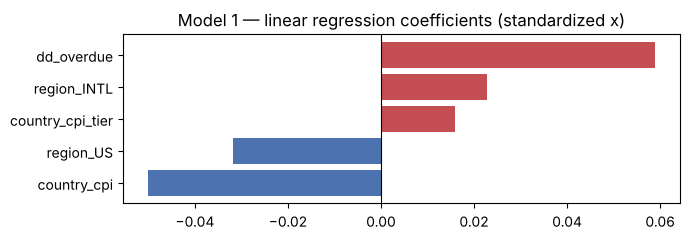

In [11]:
model_lin = run_model("1_linear_regression")
yhat = model_lin.predict(Xte_s)
print(f"y_hat on VALIDATION: min={yhat.min():.2f}, max={yhat.max():.2f}, "
      f"share outside [0,1] = {np.mean((yhat < 0) | (yhat > 1)):.1%}")
coef_lin = pd.Series(model_lin[-1].coef_, index=SELECTED).sort_values()
plt.figure(figsize=(7, 0.3 * len(coef_lin) + 1))
plt.barh(coef_lin.index, coef_lin.values, color=np.where(coef_lin > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, c="k", lw=0.8); plt.title("Model 1 — linear regression coefficients (standardized x)")
plt.tight_layout(); plt.show()

## Model 2: logistic regression

$\log\frac{P}{1-P}=\beta_0+\beta^\top x_i$, with $e^{\beta_j}$ the model's odds ratio for a one-SD increase in the preprocessed feature. `class_weight="balanced"` sets the positive-to-negative weight ratio to the training negative count divided by the training positive count: 727/70 ≈ 10.4 in `TR_A`.

With correlated variables (e.g. `country_cpi` and `country_cpi_tier`), individual coefficient signs can be misleading. Because the fit uses class weights, its probability output should be treated as a ranking score unless calibration is separately validated.

In [12]:
model_logit = run_model("2_logistic_regression")
coef_logit = pd.DataFrame({"coef": model_logit[-1].coef_.ravel()}, index=SELECTED)
coef_logit["odds_ratio"] = np.exp(coef_logit.coef)
display(coef_logit.sort_values("coef", key=np.abs, ascending=False).round(3))

2_logistic_regression: 5 variables | VALIDATION period | random-guess AP_case = AP = 0.028


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
2_logistic_regression,0.119,0.15,0.842,0.304,0.304,0.114,0.696,0.196,0.699


,coef,odds_ratio
region_US,-2.219,0.109
country_cpi,-0.847,0.429
dd_overdue,0.716,2.045
region_INTL,0.395,1.484
country_cpi_tier,-0.226,0.797


## Model 3: decision tree
Handles thresholds and interactions and can be plotted. Unstable, and the scores take only a few distinct values, so lots of ties (broken at random).

3_decision_tree: 5 variables | VALIDATION period | random-guess AP_case = AP = 0.028


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
3_decision_tree,0.062,0.076,0.66,0.174,0.261,0.146,0.261,0.188,0.869


inner-CV PR-AUC by max_depth: {2: np.float64(0.328), 3: np.float64(0.417), 4: np.float64(0.437), 5: np.float64(0.429), 6: np.float64(0.44)} -> chosen 6


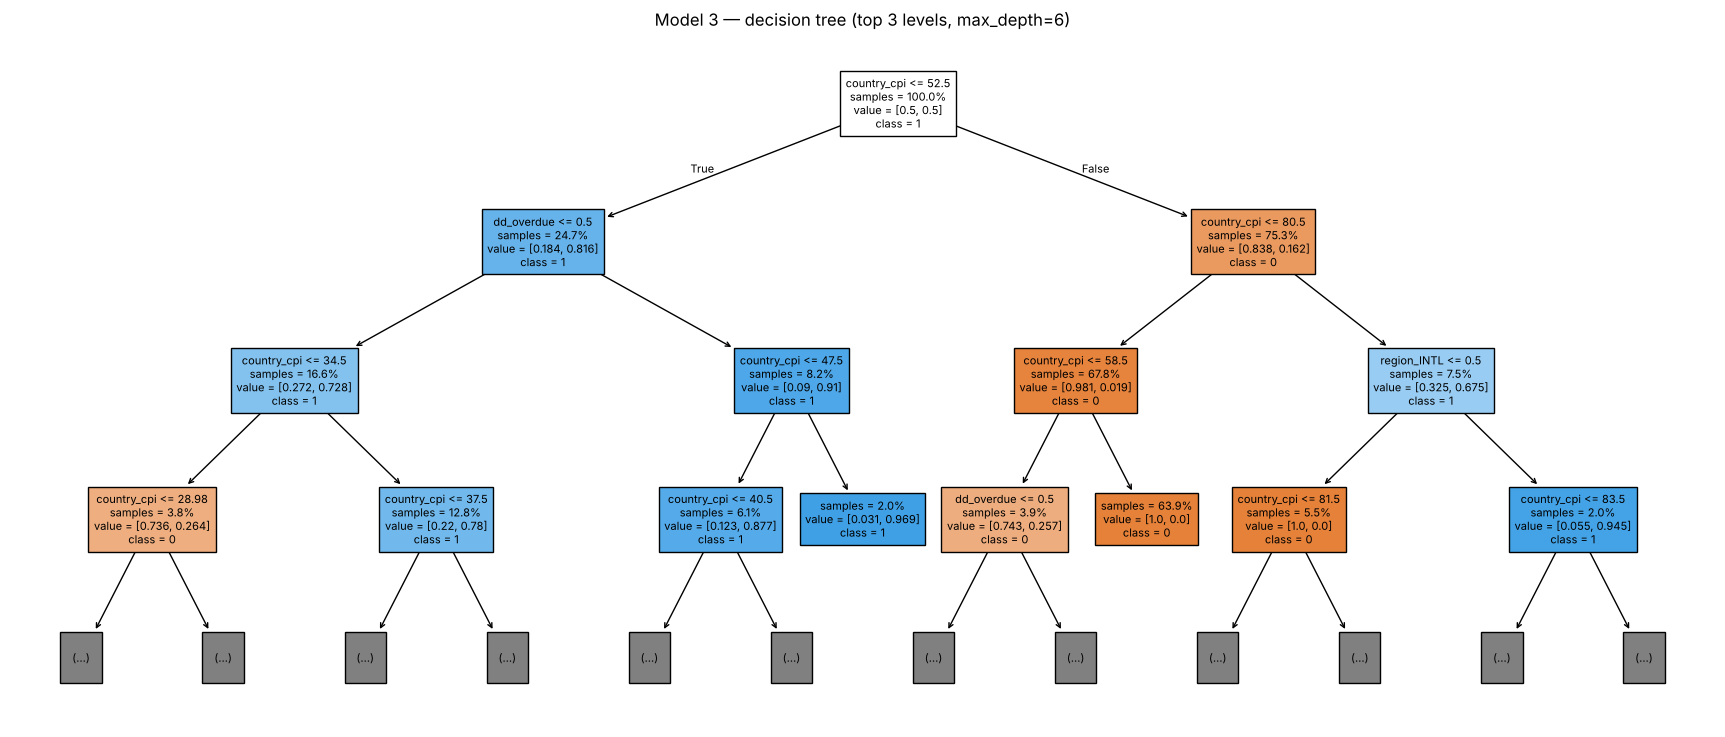

In [13]:
model_tree = run_model("3_decision_tree")
print("inner-CV PR-AUC by max_depth:", {k: round(v, 3) for k, v in model_tree.depth_cv_.items()},
      "-> chosen", model_tree.best_depth_)
plt.figure(figsize=(22, 9))
plot_tree(model_tree[-1], feature_names=SELECTED, class_names=["0", "1"], filled=True,
          max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title(f"Model 3 — decision tree (top 3 levels, max_depth={model_tree.best_depth_})"); plt.show()

## Model 4: random forest
Interpreted with permutation importance on the VALIDATION set (drop in AP when one variable is shuffled). Descriptive only: nothing is chosen from it.

4_random_forest: 5 variables | VALIDATION period | random-guess AP_case = AP = 0.028


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
4_random_forest,0.081,0.103,0.821,0.174,0.217,0.114,0.391,0.176,0.499


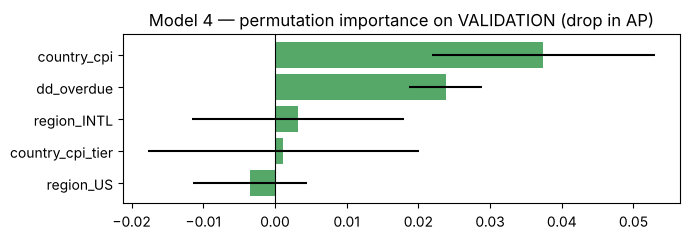

In [14]:
model_rf = run_model("4_random_forest")
pi = permutation_importance(model_rf, Xte_s, yte, scoring="average_precision", n_repeats=20, random_state=SEED)
imp_rf = pd.Series(pi.importances_mean, index=SELECTED).sort_values()
plt.figure(figsize=(7, 0.3 * len(imp_rf) + 1))
plt.barh(imp_rf.index, imp_rf.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color="#55A868")
plt.axvline(0, c="k", lw=0.8); plt.title("Model 4 — permutation importance on VALIDATION (drop in AP)")
plt.tight_layout(); plt.show()

## Model 5: gradient boosting
`HistGradientBoosting`: depth 3, learning rate 0.05, a maximum of 300 boosting iterations.

In [15]:
model_gb = run_model("5_gradient_boosting")

5_gradient_boosting: 5 variables | VALIDATION period | random-guess AP_case = AP = 0.028


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
5_gradient_boosting,0.087,0.108,0.833,0.13,0.304,0.123,0.348,0.182,0.614


## The five models on the same split

Trained on the TRAINING period (797 vendors, 70 positives in 14 case groups), evaluated on the VALIDATION period (824 vendors, 23 positives in 7 cases; random AP ≈ 0.028). With five selected variables, all country/region or DD-overdue, linear regression has the highest `AP_case` (0.125), followed by logistic regression (0.119); the tree-based models are lower (0.062–0.087). Seven cases are too few for model conclusions; see the repeated evaluation below.

,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1
model,,,,,,,,
1_linear_regression,0.125,0.158,0.840,0.304,0.391,0.109,0.696,0.188
2_logistic_regression,0.119,0.150,0.842,0.304,0.304,0.114,0.696,0.196
3_decision_tree,0.062,0.076,0.660,0.174,0.261,0.146,0.261,0.188
4_random_forest,0.081,0.103,0.821,0.174,0.217,0.114,0.391,0.176
5_gradient_boosting,0.087,0.108,0.833,0.130,0.304,0.123,0.348,0.182


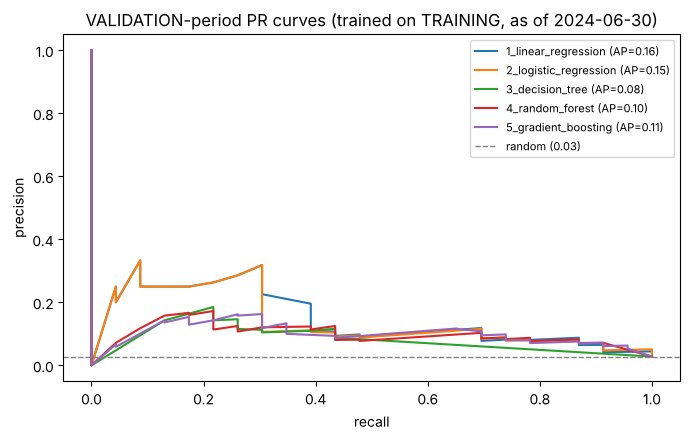

In [16]:
res = pd.DataFrame(RESULTS).set_index("model")
res.to_csv(f"{OUT}/L1_models_test_metrics.csv")
display(res[["AP_case", "AP", "roc_auc", "precision_at_k", "recall_at_2k", "precision", "recall", "f1"]].round(3))
plt.figure(figsize=(7, 4.5))
for name, s in TEST_SCORES.items():
    p, r_, _ = precision_recall_curve(yte, s)
    plt.plot(r_, p, label=f"{name} (AP={average_precision_score(yte, s):.2f})")
plt.axhline(yte.mean(), ls="--", c="grey", lw=1, label=f"random ({yte.mean():.2f})")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("VALIDATION-period PR curves (trained on TRAINING, as of 2024-06-30)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

# Unsupervised Learning: Isolation Forest

The main dataset (~20,000 records) has no labels and may contain patterns that are not in the practice set, so we also try a label-free method.

- uses all available variables in the evaluated version, without supervised variable selection
- fitted, without y, on every vendor present at the cut-off of the evaluated period (as a reviewer at that date would do), then scored on the evaluation set of that period
- fixed settings, not tuned against the labels

## Preprocessing
- winsorizing + median imputation fitted on the vendors present at the cut-off
- non-negative continuous variables with skew > 2 → $\log(1+x)$, so a long tail doesn't squeeze most records into a small range

Comparisons with a peer group (e.g. percentiles within the subregion) depend on other vendors, so they're left for Layer 2.

In [17]:
def unsup_matrix(t, names):
    # no labels used; fitted on every vendor present at t
    F_ = SNAP[t]
    Xu = pd.DataFrame(Prep().fit_transform(F_[names].values.astype(float)), columns=names, index=F_.index)
    cont_ = [c for c in names if Xu[c].nunique() > 2]
    skew_ = [c for c in cont_ if Xu[c].min() >= 0 and Xu[c].skew() > 2]
    Xu[skew_] = np.log1p(Xu[skew_])
    return Xu, cont_, skew_


XU, cont, skewed = unsup_matrix(T_VAL, FEATS)
print(f"as of {T_VAL.date()}: {len(XU)} vendors, {len(FEATS)} variables: {len(FEATS) - len(cont)} binary, "
      f"{len(cont)} continuous, {len(skewed)} log-transformed")

as of 2025-06-30: 894 vendors, 92 variables: 41 binary, 51 continuous, 25 log-transformed


## Model 6: Isolation Forest

Anomaly score = `-score_samples` (higher = easier to isolate); it is not a calibrated risk probability. The model uses 500 trees and `max_samples=256`. This exploratory section fits on the 2025-06-30 population, averages scores over 10 random seeds, checks agreement between runs, and evaluates on the VALIDATION set. The later five-seed evaluation averages 5 Isolation Forest fits per evaluation seed and period.

For the top 10 records of the VALIDATION ranking, the variables with the largest absolute standardized deviations (|z|) are listed as descriptive context. These deviations are not model-specific feature attributions.

In [18]:
from scipy.stats import spearmanr


def iforest(Xu, seeds=range(10)):
    S = np.array([-IsolationForest(n_estimators=500, max_samples=256, contamination="auto",
                                   random_state=s).fit(Xu).score_samples(Xu) for s in seeds])
    return S.mean(0), S


IF_ALL, S = iforest(XU.values)                       # every vendor present at 2025-06-30
IF_SCORE = pd.Series(IF_ALL, index=XU.index).loc[EV_VAL["rid"]].values
rho = [spearmanr(S[i], S[j])[0] for i in range(len(S)) for j in range(i + 1, len(S))]
IF_ROWS = [dict(scope=f"VALIDATION set ({len(yte)})", **rank_metrics(yte, IF_SCORE, w=W_te), seed_spearman=np.mean(rho))]
display(pd.DataFrame(IF_ROWS).set_index("scope").round(3))

Z = pd.DataFrame(StandardScaler().fit_transform(XU), columns=FEATS, index=XU.index).loc[EV_VAL["rid"]]
expl = []
for i in np.argsort(-IF_SCORE)[:10]:
    z = Z.iloc[i]
    big = z.abs().sort_values(ascending=False).head(4)
    expl.append(dict(record_id=Z.index[i], y=yte[i], score=round(IF_SCORE[i], 3),
                     top_deviations=", ".join(f"{k} ({z[k]:+.1f}σ)" for k in big.index)))
print("\nTop-10 most anomalous records in the VALIDATION set")
display(pd.DataFrame(expl))

,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,seed_spearman
scope,,,,,,
VALIDATION set (824),0.038,0.03,0.497,0.0,0.0,0.984



Top-10 most anomalous records in the VALIDATION set


,record_id,y,score,top_deviations
0,TP-DA53581D,0,0.571,"n_link_serves (+6.0σ), n_inst_links (+4.8σ), s..."
1,TP-4F739F22,0,0.563,"share_pcard_expense (+4.9σ), share_sponsor_mis..."
2,TP-5CFFFE15,0,0.561,"n_links_foreign (+24.3σ), n_eng_markets (+8.1σ..."
3,TP-74943F49,0,0.545,"n_link_serves (+6.0σ), n_inst_links (+4.8σ), n..."
4,TP-E0C9DD5E,0,0.539,"n_approver_is_sponsor (+6.6σ), n_expense_class..."
5,TP-CD389FAD,0,0.536,"remit_country_differs (+6.2σ), n_link_serves (..."
6,TP-6A89716B,0,0.534,"share_links_public (-4.3σ), n_engagements (+3...."
7,TP-DBBB4B31,0,0.533,"manual_pay_rate (+5.2σ), n_link_serves (+3.3σ)..."
8,TP-48B9CAAF,0,0.528,"share_paying_mkt_differs (+4.6σ), n_eng_market..."
9,TP-7024E8B1,0,0.528,"expert_investigator_kol (+5.0σ), manual_pay_ra..."


---
# Evaluation over 5 seeds + ablations

## Red-flag rule: payments after termination

CASE-0016 is "terminated, but payments continue". Its vendor was terminated on 2025-01-25, so under the temporal split the case belongs to the VALIDATION period. At the 2024-06-30 cut-off the termination has not happened yet, so the training data contains no positive example of this pattern at all, and the signal cannot be learned from labels. We therefore evaluate a separate rule using the vendor's own payments and termination date, both as known at the cut-off.

**Rule:** flag a vendor if it is paid in month ≥ termination month + `GRACE_MONTHS` + 1 (`GRACE_MONTHS = 1`):
- the termination month itself is skipped, payments are monthly totals
- one grace month for the final invoice

The CASE-0016 vendor has one paid month after termination, 2025-03 (`why_flagged` says "3 more month(s)"). With 2 grace months it would not be flagged. The one-month choice was informed by this labelled example, so its measured gain in the VALIDATION period is exploratory rather than an independent validation of the rule. On the main data we need to check how many vendors it flags; some may be legitimate (e.g. transitional services around the consumer healthcare demerger in `business_events`).

**Ranking:** rank percentile of the score + 2 for flagged vendors, i.e. flagged vendors first, then everyone else by score. Results are reported with and without the rule.

In [19]:
from scipy.stats import rankdata

GRACE_MONTHS = 1


def pay_offsets(t):
    # months from termination month to the last paid month, using termination and payments known at t
    term = PARTS[t]["tp"].set_index("record_id").terminated_date
    pm = PARTS[t]["pay"].groupby("record_id").month.apply(lambda s: sorted(set(s.dt.to_period("M"))))
    out = {}
    for r, d in term.dropna().items():
        offs = [(m - d.to_period("M")).n for m in pm.get(r, [])]
        out[r] = max([o for o in offs if o > 0], default=0)
    return pd.Series(out, dtype=float).reindex(SNAP[t].index).fillna(0)


PAY_OFFSET = {t_: pay_offsets(t_) for t_ in CUTOFFS}
case_of_all = {m: c.case_id for c in labels.itertuples() for m in c.members}
rows_rf = []
for t_ in CUTOFFS:
    for gm in [0, 1, 2]:
        fl = PAY_OFFSET[t_][PAY_OFFSET[t_] >= gm + 1].index
        rows_rf.append(dict(cutoff=str(t_.date()), grace_months=gm, n_flagged=len(fl),
                            flagged=", ".join(f"{r} ({case_of_all.get(r, 'not a case member')})" for r in fl)))
print("vendors flagged (payment in month >= termination month + grace + 1), by cut-off:")
display(pd.DataFrame(rows_rf))


def red_flag(s):
    # flags for the rows of an evaluation set, as known at its cut-off
    return (PAY_OFFSET[s["t"]].reindex(s["rid"]).values >= GRACE_MONTHS + 1)


def apply_rule(score, flags):
    # flagged vendors on top
    return rankdata(score) / len(score) + 2.0 * flags


for s_ in [EV_VAL, EV_TEST]:
    print(f"{s_['name']}: GRACE_MONTHS = {GRACE_MONTHS} -> {red_flag(s_).sum()} red-flag vendor(s) in the evaluation set")

vendors flagged (payment in month >= termination month + grace + 1), by cut-off:


,cutoff,grace_months,n_flagged,flagged
0,2024-06-30,0,0,
1,2024-06-30,1,0,
2,2024-06-30,2,0,
3,2025-06-30,0,1,TP-33FC40CA (CASE-0016)
4,2025-06-30,1,1,TP-33FC40CA (CASE-0016)
5,2025-06-30,2,0,
6,2026-06-30,0,1,TP-33FC40CA (CASE-0016)
7,2026-06-30,1,1,TP-33FC40CA (CASE-0016)
8,2026-06-30,2,0,


EV_VAL: GRACE_MONTHS = 1 -> 1 red-flag vendor(s) in the evaluation set
EV_TEST: GRACE_MONTHS = 1 -> 0 red-flag vendor(s) in the evaluation set


## Evaluation setup

Each evaluation seed runs the whole temporal protocol:

| period scored | trained on | scored on | what it measures |
|---|---|---|---|
| `TRAINING_cv` | 4/5 of `TR_A` (grouped, stratified 5-fold, fold split `random_state = 1000 + seed`) | the held-out fifth of `TR_A` | in-period fit, same cut-off; gives every TRAINING case a score |
| `VALIDATION` | all of `TR_A` (2024-06-30) | `EV_VAL` (2025-06-30) | out of time, one year ahead |
| `TEST` | all of `TR_B` (2025-06-30) | `EV_TEST` (2026-06-30) | out of time, one year ahead; the period the sponsor scores blind |

- **Models 1–5:** variable selection (≥ 3 of 4 votes), the tree's depth and all preprocessing are fitted on the training rows of each step only. The seed sets the inner CV splits and the models' random states. The outer temporal split is fixed, so for `VALIDATION` and `TEST` the variation across seeds comes only from these sources.
- **Isolation Forest:** label-free; fitted on every vendor present at the cut-off of the period and scored on that period's evaluation set. Five fits are averaged per evaluation seed.
- Each period is scored separately. Records of earlier-period cases are not in the evaluation set; records of later-period cases are y = 0.

Results are reported as mean [min–max] over the five seeds; these ranges are not confidence intervals. The out-of-time periods are the headline. `TRAINING_cv` is in-period and closer to the old protocol, so it is expected to look better.

Metrics, per period:

- `AP_case`: case-balanced record-level AP; `AP`: ordinary record-level AP. The reference level for both is the positive fraction of that period's evaluation set.
- `P@k`, `R@k` for k = 10, 25, 50, 100: precision and recall over records.
- `cases_half@k` for k = 25, 50, 100: number of that period's cases with at least half of their members among the top k records. This is a member-coverage diagnostic, not evaluation of predicted case groups, IoU, or one-to-one matching.
- The coverage budget for per-case results and the missed-case list is **top 100 records** (`BUDGET`). This is the largest review queue in the sponsor's scoring, and it does not depend on the labels. The old notebook used top 159, the known number of positives over all 1,002 records, which is no longer meaningful when each period has its own positives.
- Coverage by typology: the fraction of cases of each typology meeting the half-members-in-top-100 criterion.

Each model is scored with and without the red-flag rule. `run_version(names, tag)` runs all steps for every seed. Ablations skip `TRAINING_cv` (`train_cv=False`) and report the two out-of-time periods.

In [20]:
KS, KS_CASE, BUDGET = [10, 25, 50, 100], [25, 50, 100], 100
SEEDS = list(range(N_SEEDS))
ALL_MODELS = MODELS + ["6_isolation_forest"]
EVAL_PERIODS = ["TRAINING_cv", "VALIDATION", "TEST"]
EVAL_SET = {"TRAINING_cv": TR_A, "VALIDATION": EV_VAL, "TEST": EV_TEST}


def _job(Xtr, ytr, gtr, Xte, names, seed):
    import warnings
    warnings.filterwarnings("ignore")                    # joblib workers do not inherit the notebook's filter
    _, _, v3, _, _ = select_variables(Xtr, ytr, gtr, names, verbose=False, seed=seed)
    if not v3:                                           # nothing reached 3 votes: keep every variable
        v3 = list(names)
    ix = [names.index(v) for v in v3]
    out = {m: get_score(fit_model(m, Xtr[:, ix], ytr, gtr, seed), Xte[:, ix]) for m in MODELS}
    return v3, out


def eval_scores(score, ev, seed):
    y, rid = ev["y"], ev["rid"]
    n_pos = int(y.sum())
    order = np.argsort(-(score + 1e-9 * np.random.default_rng(seed).random(len(score))))
    d = {"AP_case": average_precision_score(y, score, sample_weight=ev["w"]), "AP": average_precision_score(y, score),
         "n_eval": len(y), "n_pos": n_pos, "n_cases": len(ev["cases"])}
    for k in KS:
        d[f"P@{k}"] = y[order[:k]].mean()
        d[f"R@{k}"] = y[order[:k]].sum() / n_pos
    for k in KS_CASE:
        top = set(rid[order[:k]])
        d[f"cases_half@{k}"] = sum(len(case_mem[c] & top) / len(case_mem[c]) >= 0.5 for c in ev["cases"])
    top = set(rid[order[:BUDGET]])
    per_case = {c: float(len(case_mem[c] & top) / len(case_mem[c]) >= 0.5) for c in ev["cases"]}
    return d, per_case


FROZEN = {"oof": [], "selected": []}     # filled by run_version, saved at the end


def run_version(names, tag, train_cv=True):
    col = [FEATS.index(n) for n in names]
    sub = lambda s: s["X"][:, col]
    periods = EVAL_PERIODS if train_cv else EVAL_PERIODS[1:]
    Xu = {EVAL_SET[p]["t"]: unsup_matrix(EVAL_SET[p]["t"], names)[0] for p in periods}
    XA, yA, gA = sub(TR_A), TR_A["y"], TR_A["g"]
    rows, cases, sels = [], [], []
    for seed in SEEDS:
        jobs, cv_folds = [], []
        if train_cv:
            cv_folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(XA, yA, gA))
            jobs += [(XA[tr], yA[tr], gA[tr], XA[te]) for tr, te in cv_folds]
        jobs += [(XA, yA, gA, sub(EV_VAL)), (sub(TR_B), TR_B["y"], TR_B["g"], sub(EV_TEST))]
        res_ = Parallel(n_jobs=N_JOBS)(delayed(_job)(*j, names, seed) for j in jobs)
        S, fold_of = {}, {}
        if train_cv:
            S["TRAINING_cv"] = {m: np.full(len(yA), np.nan) for m in MODELS}
            fold_of["TRAINING_cv"] = np.full(len(yA), -1)
            for f_, ((tr, te), (v3, out)) in enumerate(zip(cv_folds, res_[:5])):
                fold_of["TRAINING_cv"][te] = f_
                sels.append(dict(period="TRAINING_cv", fold=f_, variables=v3))
                for m in MODELS:
                    S["TRAINING_cv"][m][te] = out[m]
        for p, (v3, out) in zip(["VALIDATION", "TEST"], res_[-2:]):
            S[p], fold_of[p] = dict(out), np.full(len(EVAL_SET[p]["y"]), -1)
            sels.append(dict(period=p, fold=-1, variables=v3))
        for s_ in sels[-(7 if train_cv else 2):]:
            FROZEN["selected"].append(dict(version=tag, seed=seed, period=s_["period"], fold=s_["fold"],
                                           n_vars=len(s_["variables"]), variables=s_["variables"]))
        for p in periods:
            ev = EVAL_SET[p]
            if_all = iforest(Xu[ev["t"]].values, seeds=range(seed * 10, seed * 10 + 5))[0]
            S[p]["6_isolation_forest"] = pd.Series(if_all, index=Xu[ev["t"]].index).loc[ev["rid"]].values
            flags = red_flag(ev)
            FROZEN["oof"].append(pd.DataFrame({"version": tag, "period": p, "cutoff": str(ev["t"].date()), "seed": seed,
                                               "record_id": ev["rid"], "y": ev["y"], "group_id": ev["g"], "fold": fold_of[p],
                                               "red_flag": flags.astype(int), **{f"score_{m}": S[p][m] for m in ALL_MODELS}}))
            n_sel = [len(s_["variables"]) for s_ in sels[-(7 if train_cv else 2):] if s_["period"] == p]
            for m in ALL_MODELS:
                nv = np.mean(n_sel) if m in MODELS else len(names)
                for rule in (False, True):
                    d, pc = eval_scores(apply_rule(S[p][m], flags) if rule else S[p][m], ev, seed)
                    rows.append(dict(version=tag, period=p, rule=rule, model=m, seed=seed, n_vars_mean=nv, **d))
                    cases.append(dict(version=tag, period=p, rule=rule, model=m, seed=seed, **pc))
        print(f"  [{tag}] seed {seed + 1}/{len(SEEDS)} done")
    return pd.DataFrame(rows), pd.DataFrame(cases), sels


METRIC_COLS = (["AP_case", "AP"] + [f"P@{k}" for k in KS] + [f"R@{k}" for k in KS] +
               [f"cases_half@{k}" for k in KS_CASE])


def summarize(rows):
    g = rows.groupby(["version", "period", "rule", "model"], sort=False)[METRIC_COLS]
    mean, lo, hi = g.mean(), g.min(), g.max()
    fmt = mean.copy().astype(object)
    for c in METRIC_COLS:
        nd = 1 if c.startswith("cases") else 3
        fmt[c] = [f"{a:.{nd}f} [{b:.{nd}f}–{e:.{nd}f}]" for a, b, e in zip(mean[c], lo[c], hi[c])]
    return mean, fmt


def typology_table(cases):
    long = cases.melt(id_vars=["version", "period", "rule", "model", "seed"], var_name="case_id",
                      value_name="hit").dropna(subset=["hit"])
    long = long.assign(typology=long.case_id.map(case_typ).str.split("|")).explode("typology")
    return long.groupby(["version", "period", "rule", "model", "typology"]).hit.mean().unstack("typology")


ref = pd.DataFrame([dict(period=p, cutoff=str(s["t"].date()), n_eval=len(s["y"]), n_pos=int(s["y"].sum()),
                         cases=len(s["cases"]), random_AP=round(s["y"].mean(), 3)) for p, s in EVAL_SET.items()])
print("evaluation sets (random ranking: AP_case = AP ≈ positive fraction)")
display(ref)

evaluation sets (random ranking: AP_case = AP ≈ positive fraction)


,period,cutoff,n_eval,n_pos,cases,random_AP
0,TRAINING_cv,2024-06-30,797,70,16,0.088
1,VALIDATION,2025-06-30,824,23,7,0.028
2,TEST,2026-06-30,909,66,10,0.073


## Full version, 5 seeds

Report mean [min–max] across the five evaluation seeds, separately for each period.

1. Record-ranking and case-member-coverage metrics without the rule, per period.
2. Before / after comparison for the red-flag rule.
3. Coverage by typology: fraction of cases with at least half their members in the top 100 records, out-of-time periods.
4. Feature-selection frequency over all training fits (5 in-period CV folds + the VALIDATION and TEST steps, per seed), as a measure of selection stability.

  [full] seed 1/5 done


  [full] seed 2/5 done


  [full] seed 3/5 done


  [full] seed 4/5 done


  [full] seed 5/5 done
time: 12.5 min

FULL version, NO rule — TRAINING_cv (n=797, positives=70, cases=16, random AP ≈ 0.088) — mean [min–max] over seeds


,AP_case,AP,P@10,P@25,P@50,P@100,R@100,cases_half@25,cases_half@50,cases_half@100
model,,,,,,,,,,
1_linear_regression,0.360 [0.296–0.442],0.191 [0.171–0.220],0.260 [0.000–0.400],0.248 [0.120–0.360],0.200 [0.140–0.260],0.178 [0.120–0.230],0.254 [0.171–0.329],4.4 [3.0–6.0],5.8 [4.0–8.0],8.4 [7.0–10.0]
2_logistic_regression,0.325 [0.213–0.421],0.190 [0.155–0.229],0.220 [0.100–0.300],0.200 [0.120–0.280],0.204 [0.100–0.360],0.180 [0.130–0.220],0.257 [0.186–0.314],3.6 [2.0–5.0],5.6 [3.0–10.0],7.8 [5.0–10.0]
3_decision_tree,0.268 [0.203–0.368],0.195 [0.158–0.232],0.080 [0.000–0.300],0.176 [0.080–0.280],0.196 [0.120–0.320],0.190 [0.070–0.290],0.271 [0.100–0.414],2.0 [0.0–6.0],4.8 [3.0–7.0],7.2 [4.0–10.0]
4_random_forest,0.269 [0.214–0.356],0.201 [0.166–0.237],0.140 [0.000–0.300],0.136 [0.080–0.280],0.116 [0.060–0.200],0.192 [0.150–0.290],0.274 [0.214–0.414],1.2 [1.0–2.0],3.2 [2.0–6.0],6.8 [4.0–12.0]
5_gradient_boosting,0.273 [0.192–0.384],0.208 [0.174–0.249],0.120 [0.000–0.300],0.176 [0.080–0.320],0.156 [0.080–0.260],0.194 [0.160–0.240],0.277 [0.229–0.343],2.8 [2.0–5.0],4.0 [2.0–7.0],6.4 [4.0–9.0]
6_isolation_forest,0.352 [0.346–0.358],0.174 [0.172–0.177],0.320 [0.300–0.400],0.312 [0.280–0.320],0.208 [0.200–0.220],0.200 [0.190–0.220],0.286 [0.271–0.314],5.6 [5.0–6.0],6.0 [6.0–6.0],8.0 [8.0–8.0]


... (8 outputs left out)


Case coverage by typology — TEST (share of cases with >= half members in the top 100; mean over seeds)


model,1_linear_regression,2_logistic_regression,3_decision_tree,4_random_forest,5_gradient_boosting,6_isolation_forest,n_cases
typology,,,,,,,
SPONSOR_APPROVER_COUPLING,0.3,0.3,0.2,0.5,0.5,0.25,4
APPROVER_CONCENTRATION,0.0,0.0,0.0,0.0,0.0,0.00,2
BRIDGE_ENTITY,0.1,0.1,0.0,0.0,0.0,0.50,2
COMMON_BENEFICIAL_OWNER,0.6,0.6,0.4,1.0,1.0,0.50,2
ACTIVITY_TIMING_CONCENTRATION,0.1,0.1,0.5,0.6,0.5,0.00,2
DENSE_MULTI_RELATION_CLUSTER,0.6,0.6,0.3,1.0,0.6,0.00,2
OWNERSHIP_OPERATIONAL_OVERLAP,0.1,0.1,0.2,0.5,0.5,0.00,2
RAPID_ONBOARDING_LINKED,0.5,0.6,0.3,0.6,0.9,0.50,2
GEOGRAPHY_LINKED_CONCENTRATION,1.0,1.0,0.0,1.0,1.0,0.00,1



Selection frequency by training step (TRAINING_cv: 25 fits on 4/5 of TR_A; VALIDATION: TR_A; TEST: TR_B)


,TRAINING_cv,VALIDATION,TEST
country_cpi_tier,0.80,1.0,1.0
region_US,0.64,1.0,1.0
dd_overdue,0.60,1.0,1.0
region_INTL,0.56,1.0,1.0
country_cpi,0.52,1.0,0.0
q_public_official_interaction,0.36,0.2,0.0
n_link_serves,0.20,0.0,1.0
addr_coworking,0.32,0.2,0.0
share_commission_cash,0.24,0.2,0.2
is_terminated,0.24,0.0,0.0


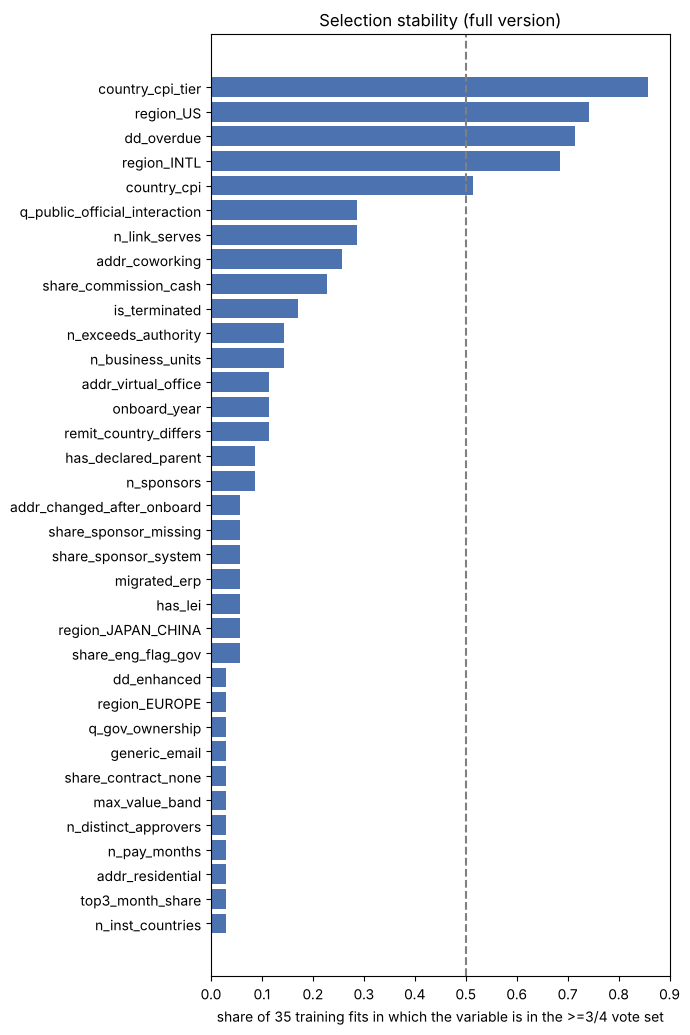

In [21]:
import time
t0 = time.time()
rows_full, cases_full, sels_full = run_version(FEATS, "full")
print(f"time: {(time.time() - t0) / 60:.1f} min")

mean_full, fmt_full = summarize(rows_full)
SHOW = ["AP_case", "AP", "P@10", "P@25", "P@50", "P@100", "R@100", "cases_half@25", "cases_half@50", "cases_half@100"]
for p in EVAL_PERIODS:
    s_ = EVAL_SET[p]
    print(f"\nFULL version, NO rule — {p} (n={len(s_['y'])}, positives={s_['y'].sum()}, cases={len(s_['cases'])}, "
          f"random AP ≈ {s_['y'].mean():.3f}) — mean [min–max] over seeds")
    display(fmt_full.xs(("full", p, False), level=["version", "period", "rule"])[SHOW])

ba = mean_full[["AP_case", "AP", "cases_half@100"]].droplevel("version").unstack("rule")
ba.columns = [f"{m} | {'with rule' if r else 'no rule'}" for m, r in ba.columns]
for m in ["AP_case", "AP", "cases_half@100"]:
    ba[f"{m} | change"] = ba[f"{m} | with rule"] - ba[f"{m} | no rule"]
print("\nBefore / after the red-flag rule (mean over seeds)")
display(ba[[c for m in ["AP_case", "AP", "cases_half@100"] for c in ba.columns if c.startswith(m + " |")]].round(3))

typ_full = typology_table(cases_full).xs(("full", False), level=["version", "rule"])
n_cases_typ = {p: pd.Series([t for c in EVAL_SET[p]["cases"] for t in case_typ[c].split("|")]).value_counts()
               for p in EVAL_PERIODS}
for p in ["VALIDATION", "TEST"]:
    print(f"\nCase coverage by typology — {p} (share of cases with >= half members in the top {BUDGET}; mean over seeds)")
    t_ = typ_full.xs(p, level="period").T.dropna(how="all")
    display(t_.assign(n_cases=n_cases_typ[p]).sort_values("n_cases", ascending=False).round(2))

stab = pd.Series([v for s in sels_full for v in s["variables"]]).value_counts() / len(sels_full)
stab = stab.reindex(FEATS).fillna(0).sort_values(ascending=False)
stab.rename("selection_frequency").to_csv(f"{OUT}/L1_selection_stability.csv")
rows_full.to_csv(f"{OUT}/L1_full_seed_metrics.csv", index=False)
cases_full.to_csv(f"{OUT}/L1_full_seed_cases.csv", index=False)
sel_by_step = pd.DataFrame({p: pd.Series([v for s in sels_full if s["period"] == p for v in s["variables"]]).value_counts()
                            / sum(s["period"] == p for s in sels_full) for p in EVAL_PERIODS}).fillna(0)
print("\nSelection frequency by training step (TRAINING_cv: 25 fits on 4/5 of TR_A; VALIDATION: TR_A; TEST: TR_B)")
display(sel_by_step.loc[stab.index[stab > 0]].head(25).round(2))
top = stab[stab > 0].head(35)[::-1]
plt.figure(figsize=(7, 0.27 * len(top) + 1))
plt.barh(top.index, top.values, color="#4C72B0")
plt.axvline(0.5, ls="--", c="grey")
plt.xlabel(f"share of {len(sels_full)} training fits in which the variable is in the >=3/4 vote set")
plt.title("Selection stability (full version)"); plt.tight_layout()
plt.savefig(f"{OUT}/L1_selection_stability.png", dpi=130); plt.show()

### Where the change from the snapshot notebook comes from

A diagnostic, not part of the baseline. It uses one fixed model (GB on all variables, no selection, 3 seeds) so that the protocols can be compared directly:

1. **old protocol**: random grouped 5-fold CV over all 1,002 records, features as of 2026-06-30, all 33 cases as positives. The pooled out-of-fold ranking is then evaluated period by period: only that period's cases count as positives, and the members of the other periods' cases are removed.
2. **same rows, two cut-offs**: in-period CV on `TR_A` (TRAINING cases), once with the as-of-2024-06-30 values and once with the 2026-06-30 values of the same vendors. The difference measures how much future information in the features was helping.
3. **out of time**: GB trained on `TR_A` → `EV_VAL`, and on `TR_B` → `EV_TEST`, as in the main protocol but without variable selection.

In [22]:
def gb_all(seed):
    return make_pipeline(Prep(), HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                                l2_regularization=1.0, class_weight="balanced",
                                                                random_state=seed))


def gb_oof(X, y, g, seed):
    s = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(X, y, g):
        s[te] = gb_all(seed).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return s


ALL = make_set(T_TEST, list(case_tab.case_id), name="ALL")   # old protocol: all records, all cases
diag = []
for seed in range(3):
    s_old = gb_oof(ALL["X"], ALL["y"], ALL["g"], seed)
    for p in PERIOD_ORDER:
        keep = ~np.isin(ALL["rid"], list(members(case_tab.case_id) - members(CASES_IN[p])))
        yy = np.isin(ALL["rid"][keep], list(members(CASES_IN[p]))).astype(int)
        ww = case_weight_vector(ALL["rid"][keep], yy, CASES_IN[p])
        diag.append(dict(protocol="1 old: random CV, 2026-06-30 features", period=p, seed=seed,
                         AP_case=average_precision_score(yy, s_old[keep], sample_weight=ww),
                         AP=average_precision_score(yy, s_old[keep]), random=yy.mean()))
    for lab, X_ in [("2a in-period CV, as-of-2024-06-30 values", TR_A["X"]),
                    ("2b in-period CV, 2026-06-30 values of the same rows", SNAP[T_TEST].loc[TR_A["rid"], FEATS].values)]:
        s_ = gb_oof(X_, TR_A["y"], TR_A["g"], seed)
        diag.append(dict(protocol=lab, period="TRAINING", seed=seed, AP_case=average_precision_score(
            TR_A["y"], s_, sample_weight=TR_A["w"]), AP=average_precision_score(TR_A["y"], s_), random=TR_A["y"].mean()))
    for p, tr_, ev_ in [("VALIDATION", TR_A, EV_VAL), ("TEST", TR_B, EV_TEST)]:
        s_ = gb_all(seed).fit(tr_["X"], tr_["y"]).predict_proba(ev_["X"])[:, 1]
        diag.append(dict(protocol="3 out of time (temporal)", period=p, seed=seed,
                         AP_case=average_precision_score(ev_["y"], s_, sample_weight=ev_["w"]),
                         AP=average_precision_score(ev_["y"], s_), random=ev_["y"].mean()))
diag = pd.DataFrame(diag)
diag_tab = diag.groupby(["protocol", "period"], sort=False)[["AP_case", "AP", "random"]].mean().round(3)
diag_tab.to_csv(f"{OUT}/L1_protocol_diagnostic.csv")
display(diag_tab.unstack("period").reindex(columns=PERIOD_ORDER, level="period"))

AP_case                         AP                     random                  
period                                             TRAINING VALIDATION   TEST TRAINING VALIDATION   TEST TRAINING VALIDATION   TEST
protocol                                                                                                                           
1 old: random CV, 2026-06-30 features                 0.540      0.365  0.562    0.439      0.396  0.549    0.077      0.027  0.073
2a in-period CV, as-of-2024-06-30 values              0.332        NaN    NaN    0.249        NaN    NaN    0.088        NaN    NaN
2b in-period CV, 2026-06-30 values of the same ...    0.342        NaN    NaN    0.246        NaN    NaN    0.088        NaN    NaN
3 out of time (temporal)                                NaN      0.215  0.432      NaN      0.309  0.354      NaN      0.028  0.073

## Paired model comparison

Within each seed and period the supervised models use the same training rows, so we compare per-seed differences and count how many of the five are positive. Here LR means logistic regression; linear regression is reported separately. For the out-of-time periods the split is fixed, so the five seeds only vary the inner CV splits and model randomness. These are descriptive comparisons, not independent replications or a significance test.

Metrics: `AP_case`, record P@10 / 25 / 50 / 100, and `cases_half@100`, for VALIDATION and TEST. This comparison excludes the red-flag rule to isolate model rankings.

In [23]:
base = rows_full[~rows_full.rule]
pairs = [("5_gradient_boosting", "2_logistic_regression", "GB − LR"),
         ("4_random_forest", "2_logistic_regression", "RF − LR"),
         ("5_gradient_boosting", "4_random_forest", "GB − RF")]
out = []
for p in ["VALIDATION", "TEST"]:
    for metric in ["AP_case", "P@10", "P@25", "P@50", "P@100", "cases_half@100"]:
        pv = base[base.period == p].pivot(index="seed", columns="model", values=metric)
        for a_, b_, lab_ in pairs:
            d_ = pv[a_] - pv[b_]
            out.append(dict(period=p, metric=metric, pair=lab_, **{f"seed {s}": round(v, 3) for s, v in d_.items()},
                            mean=round(d_.mean(), 3), n_positive=f"{int((d_ > 0).sum())} / {len(d_)}"))
paired = pd.DataFrame(out)
paired.to_csv(f"{OUT}/L1_paired_model_comparison.csv", index=False)
display(paired)

,period,metric,pair,seed 0,seed 1,seed 2,seed 3,seed 4,mean,n_positive
0,VALIDATION,AP_case,GB − LR,-0.032,-0.036,-0.032,-0.032,-0.032,-0.033,0 / 5
1,VALIDATION,AP_case,RF − LR,-0.038,-0.006,-0.038,-0.036,-0.037,-0.031,0 / 5
2,VALIDATION,AP_case,GB − RF,0.006,-0.030,0.006,0.004,0.004,-0.002,4 / 5
3,VALIDATION,P@10,GB − LR,-0.300,0.000,-0.200,-0.200,-0.200,-0.180,0 / 5
4,VALIDATION,P@10,RF − LR,-0.300,0.000,-0.200,-0.200,-0.200,-0.180,0 / 5
5,VALIDATION,P@10,GB − RF,0.000,0.000,0.000,0.000,0.000,0.000,0 / 5
6,VALIDATION,P@25,GB − LR,-0.120,-0.080,-0.120,-0.120,-0.160,-0.120,0 / 5
7,VALIDATION,P@25,RF − LR,-0.120,0.000,-0.120,-0.080,-0.120,-0.088,0 / 5
8,VALIDATION,P@25,GB − RF,0.000,-0.080,0.000,-0.040,-0.040,-0.032,0 / 5
9,VALIDATION,P@50,GB − LR,0.000,-0.040,0.000,0.000,0.000,-0.008,0 / 5


## Ablations
Drop one group of variables and rerun the two out-of-time steps (same seeds, selection redone in every training step, Isolation Forest refit on the smaller set). The in-period `TRAINING_cv` step is skipped for ablations.

| version | removed |
|---|---|
| −T | `is_terminated`, `tenure_years`, `onboard_year` |
| −T_ext | −T + `onboarded_last_3y`, `dd_overdue` (onboarding date and `status == 'active'` again) |
| −C | the 15 employee / institution / market variables |
| −D | the 8 country / region variables |
| −exceeds_authority | `n_exceeds_authority` |
| −role_missing | `n_approver_role_missing` |
| −authority_both | both (= conservative baseline) |

Tables are without the rule, `AP_case` first, for VALIDATION and TEST separately. The typology heat map pools the cases of both out-of-time periods (each case belongs to exactly one). Each difference measures the effect of removing a group and rerunning selection and fitting; it is not the isolated contribution of one feature with the rest of the pipeline held fixed.

Why T: in the snapshot version, 60% of non-case vendors were terminated vs 18% of case members, and case members were onboarded later. Part of that came from measuring status at 2026-06-30 for cases that emerged years earlier. With as-of-t features, termination, tenure and the three-year window are measured at each cut-off, so the T ablations now test what remains of this association out of time. They do not establish the cause of the association.

  [-T] seed 1/5 done


  [-T] seed 2/5 done


  [-T] seed 3/5 done


  [-T] seed 4/5 done


  [-T] seed 5/5 done


  [-T_ext] seed 1/5 done


... (36 outputs left out)


Change vs full version (mean over seeds)
AP_case


version                              -T  -T_ext     -C     -D  -exceeds_authority  -role_missing  -authority_both
period     model                                                                                                 
VALIDATION 1_linear_regression   -0.002  -0.046  0.022  0.072               0.018          0.000            0.018
           2_logistic_regression  0.003  -0.046  0.028  0.044               0.021          0.000            0.021
           3_decision_tree        0.001  -0.027  0.003  0.078               0.001          0.000            0.001
           4_random_forest        0.001  -0.026  0.012  0.242               0.018          0.000            0.018
           5_gradient_boosting   -0.003  -0.021  0.002  0.209               0.009          0.000            0.009
           6_isolation_forest    -0.002  -0.003 -0.008 -0.003              -0.001         -0.001           -0.000
TEST       1_linear_regression   -0.031   0.047 -0.011  0.117               0.000         -0.006           -0.006
           2_logistic_regression -0.042   0.053 -0.022  0.167               0.000         -0.007           -0.007
           3_decision_tree       -0.019   0.030 -0.014  0.101               0.000         -0.002           -0.002
           4_random_forest       -0.054   0.020 -0.053  0.270               0.000         -0.001           -0.001
           5_gradient_boosting   -0.035   0.050 -0.028  0.305               0.000         -0.004           -0.004
           6_isolation_forest    -0.001  -0.006 -0.088 -0.002              -0.016         -0.008           -0.018

cases_half@100


version                            -T  -T_ext   -C   -D  -exceeds_authority  -role_missing  -authority_both
period     model                                                                                           
VALIDATION 1_linear_regression    0.0     0.6  0.2  2.4                 0.4            0.0              0.4
           2_logistic_regression -0.4     0.6  0.0  1.4                 0.4            0.0              0.4
           3_decision_tree       -0.2    -0.2 -0.2  0.2                 0.0            0.0              0.0
           4_random_forest       -0.2    -0.2 -0.2  1.4                 0.0            0.0              0.0
           5_gradient_boosting   -0.4    -0.4  0.2  1.6                 0.0            0.0              0.0
           6_isolation_forest     0.0     0.0 -1.0  0.0                 0.0            0.0              0.0
TEST       1_linear_regression   -1.4     1.6 -2.0  1.6                 0.0            0.0              0.0
           2_logistic_regression -1.6     1.4 -2.2  1.6                 0.0            0.0              0.0
           3_decision_tree       -0.2     2.0  0.2  2.6                 0.0            0.0              0.0
           4_random_forest       -2.6    -0.6 -2.6  1.4                 0.0            0.0              0.0
           5_gradient_boosting   -2.0     0.2 -2.8  1.0                 0.0            0.0              0.0
           6_isolation_forest     0.0     0.0 -1.6  0.0                -1.0            0.0             -1.0

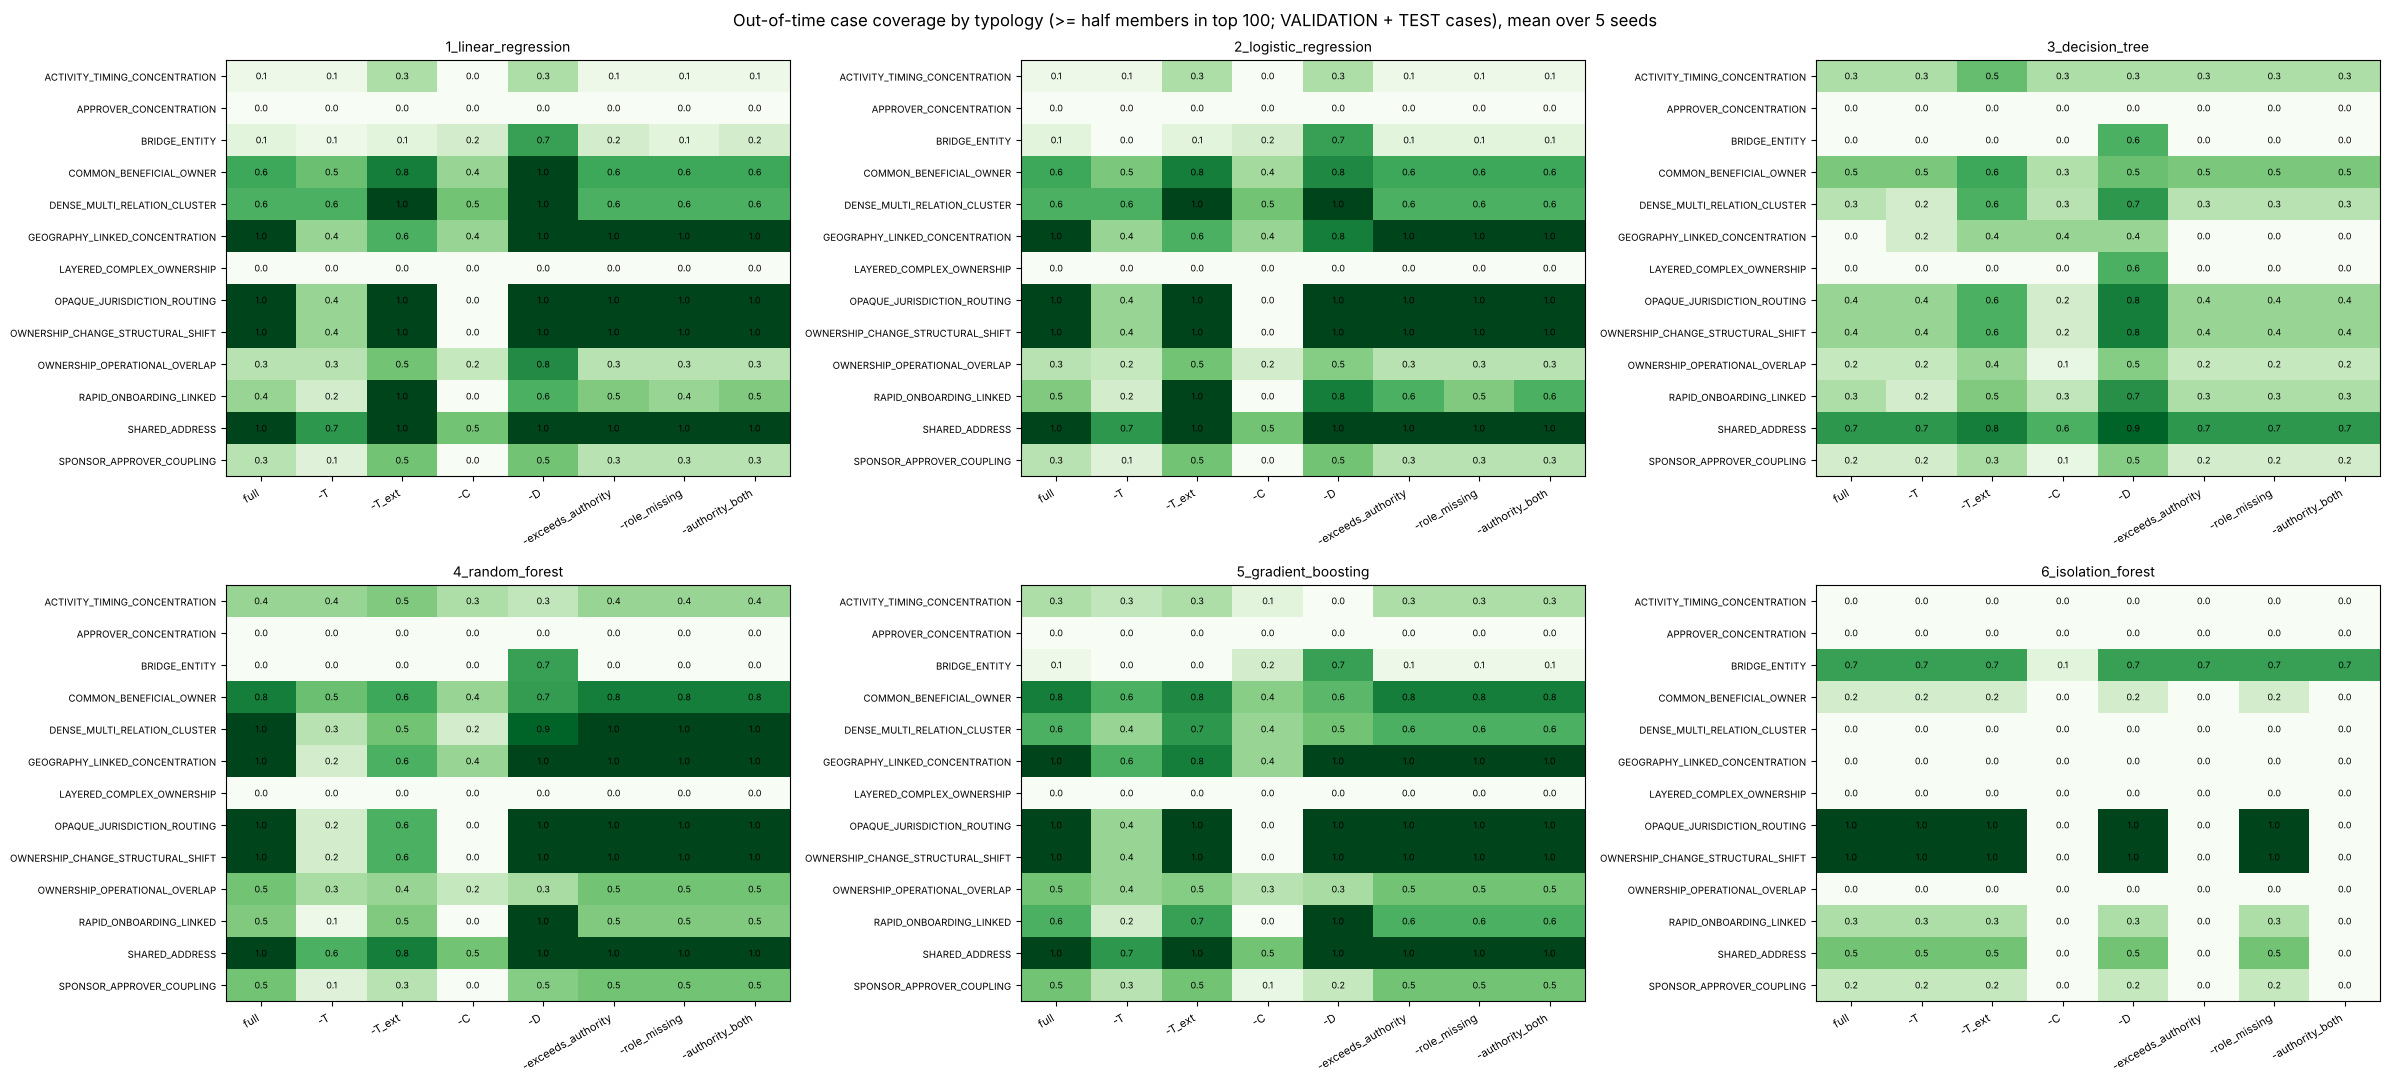

In [24]:
GROUPS = {
    "-T": ["is_terminated", "tenure_years", "onboard_year"],
    "-T_ext": ["is_terminated", "tenure_years", "onboard_year", "onboarded_last_3y", "dd_overdue"],
    "-C": ["n_exceeds_authority", "n_business_units", "n_sponsors", "n_inst_links", "n_link_serves",
           "n_inst_countries", "share_sponsor_system", "share_cross_border", "share_paying_mkt_differs",
           "n_links_foreign", "share_links_public", "n_eng_markets", "n_distinct_approvers", "n_approver_is_sponsor",
           "n_approver_role_missing"],
    "-D": ["country_cpi", "country_cpi_tier", "country_bo_access_low", "country_sanctioned",
           "region_US", "region_EUROPE", "region_JAPAN_CHINA", "region_INTL"],
    "-exceeds_authority": ["n_exceeds_authority"],
    "-role_missing": ["n_approver_role_missing"],
    "-authority_both": ["n_exceeds_authority", "n_approver_role_missing"],
}
for k, v in GROUPS.items():
    missing = [c for c in v if c not in FEATS]
    assert not missing, (k, missing)

all_rows, all_cases = [rows_full[rows_full.period != "TRAINING_cv"]], [cases_full[cases_full.period != "TRAINING_cv"]]
t0 = time.time()
for tag, drop in GROUPS.items():
    names = [c for c in FEATS if c not in drop]
    r_, c_, _ = run_version(names, tag, train_cv=False)
    all_rows.append(r_); all_cases.append(c_)
print(f"time: {(time.time() - t0) / 60:.1f} min")
abl_rows, abl_cases = pd.concat(all_rows), pd.concat(all_cases)
abl_rows.to_csv(f"{OUT}/L1_ablation_seed_metrics.csv", index=False)
abl_cases.to_csv(f"{OUT}/L1_ablation_seed_cases.csv", index=False)

abl_mean, abl_fmt = summarize(abl_rows)
abl_mean, abl_fmt = abl_mean.xs(False, level="rule"), abl_fmt.xs(False, level="rule")
order_v = ["full"] + list(GROUPS)
for p in ["VALIDATION", "TEST"]:
    for c, lab_ in [("AP_case", "AP_case (main)"), ("cases_half@100", f"cases with >= half members in the top {BUDGET}")]:
        print(f"\nAblation — {p} — {lab_}, mean [min–max] over seeds")
        display(abl_fmt[c].xs(p, level="period").unstack("version")[order_v])
delta = abl_mean[["AP_case", "AP", "cases_half@100"]].unstack("version")
print("\nChange vs full version (mean over seeds)")
for c in ["AP_case", "cases_half@100"]:
    d_ = delta[c][order_v].sub(delta[c]["full"], axis=0).drop(columns="full")
    print(c); display(d_.round(3))

# out-of-time typology coverage: pool VALIDATION and TEST cases
oot = abl_cases[~abl_cases.rule].drop(columns="period")
long = oot.melt(id_vars=["version", "rule", "model", "seed"], var_name="case_id", value_name="hit").dropna(subset=["hit"])
long = long.assign(typology=long.case_id.map(case_typ).str.split("|")).explode("typology")
typ_abl = long.groupby(["version", "model", "typology"]).hit.mean().unstack("typology")
typ_abl.to_csv(f"{OUT}/L1_ablation_by_typology.csv")
fig, axes = plt.subplots(2, 3, figsize=(24, 11))
for ax, m in zip(axes.ravel(), ALL_MODELS):
    t = typ_abl.xs(m, level="model").reindex(order_v).T
    im = ax.imshow(t.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(order_v))); ax.set_xticklabels(order_v, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(t.index))); ax.set_yticklabels(t.index, fontsize=7)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5)
    ax.set_title(m, fontsize=10)
fig.suptitle(f"Out-of-time case coverage by typology (>= half members in top {BUDGET}; VALIDATION + TEST cases), "
             "mean over 5 seeds", fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT}/L1_ablation_typology.png", dpi=130); plt.show()

## Two Layer 1 baselines

- **full**: all Layer 1 variables are eligible for supervised selection. Models 1–5 use the step-specific selected subset; Isolation Forest uses all variables in this version.
- **conservative**: exclude `n_exceeds_authority` and `n_approver_role_missing` before selection or fitting. This is a sensitivity analysis for unusually clean authority signals, not an established estimate of performance on the main dataset.

Layer 2 should be compared against both using the same temporal steps, cut-offs and metric definitions. Results are shown per out-of-time period without and with the rule, followed by the paired model comparison on the conservative version.

In [25]:
KEYS = ["AP_case", "AP", "P@10", "P@25", "P@50", "P@100", "cases_half@100"]
bl_rows = abl_rows[abl_rows.version.isin(["full", "-authority_both"])].replace(
    {"version": {"full": "full", "-authority_both": "conservative"}})
_, bl_fmt = summarize(bl_rows)
for p in ["VALIDATION", "TEST"]:
    for rule in (False, True):
        t = bl_fmt[KEYS].xs((p, rule), level=["period", "rule"]).unstack("version")
        t.columns = [f"{m} | {v}" for m, v in t.columns]
        print(f"\nLayer 1 baselines — {p} — {'WITH' if rule else 'WITHOUT'} the red-flag rule, mean [min–max] over seeds")
        display(t[[f"{m} | {v}" for m in KEYS for v in ["full", "conservative"]]])
bl_rows.to_csv(f"{OUT}/L1_baselines_seed_metrics.csv", index=False)

# paired comparison, conservative baseline
cons = abl_rows[(abl_rows.version == "-authority_both") & (~abl_rows.rule)]
out = []
for p in ["VALIDATION", "TEST"]:
    for metric in ["AP_case", "P@25", "P@50", "P@100", "cases_half@100"]:
        pv = cons[cons.period == p].pivot(index="seed", columns="model", values=metric)
        for a_, b_, lab_ in pairs:
            d_ = pv[a_] - pv[b_]
            out.append(dict(period=p, metric=metric, pair=lab_, mean=round(d_.mean(), 3),
                            n_positive=f"{int((d_ > 0).sum())} / {len(d_)}"))
print("\nPaired model comparison on the CONSERVATIVE baseline")
display(pd.DataFrame(out))


Layer 1 baselines — VALIDATION — WITHOUT the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@100 | full,cases_half@100 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.130 [0.125–0.151],0.148 [0.125–0.171],0.159 [0.158–0.162],0.171 [0.158–0.192],0.220 [0.200–0.300],0.200 [0.100–0.300],0.264 [0.200–0.280],0.264 [0.200–0.280],0.172 [0.140–0.180],0.172 [0.140–0.200],0.110 [0.100–0.150],0.118 [0.100–0.150],3.4 [3.0–5.0],3.8 [3.0–5.0]
2_logistic_regression,0.125 [0.119–0.149],0.146 [0.119–0.176],0.155 [0.150–0.173],0.173 [0.150–0.198],0.220 [0.200–0.300],0.220 [0.200–0.300],0.272 [0.240–0.280],0.256 [0.200–0.280],0.148 [0.140–0.180],0.172 [0.140–0.200],0.114 [0.100–0.170],0.124 [0.100–0.170],3.4 [3.0–5.0],3.8 [3.0–5.0]
3_decision_tree,0.075 [0.061–0.101],0.076 [0.057–0.101],0.099 [0.076–0.144],0.101 [0.072–0.144],0.060 [0.000–0.300],0.160 [0.000–0.300],0.160 [0.080–0.240],0.160 [0.080–0.240],0.144 [0.120–0.180],0.136 [0.080–0.180],0.110 [0.090–0.160],0.104 [0.080–0.160],3.0 [2.0–4.0],3.0 [2.0–4.0]
4_random_forest,0.094 [0.081–0.144],0.113 [0.081–0.144],0.119 [0.104–0.173],0.135 [0.104–0.173],0.040 [0.000–0.200],0.120 [0.000–0.200],0.184 [0.160–0.240],0.200 [0.160–0.240],0.132 [0.120–0.180],0.136 [0.120–0.180],0.110 [0.100–0.150],0.116 [0.100–0.150],3.2 [3.0–4.0],3.2 [3.0–4.0]
5_gradient_boosting,0.092 [0.087–0.113],0.101 [0.087–0.113],0.110 [0.108–0.117],0.116 [0.108–0.129],0.040 [0.000–0.200],0.120 [0.000–0.200],0.152 [0.120–0.160],0.168 [0.120–0.200],0.140 [0.140–0.140],0.140 [0.140–0.140],0.098 [0.090–0.120],0.106 [0.090–0.120],3.2 [3.0–4.0],3.2 [3.0–4.0]
6_isolation_forest,0.038 [0.037–0.039],0.038 [0.036–0.039],0.030 [0.029–0.031],0.030 [0.029–0.031],0.000 [0.000–0.000],0.000 [0.000–0.000],0.000 [0.000–0.000],0.000 [0.000–0.000],0.024 [0.000–0.040],0.028 [0.020–0.040],0.030 [0.020–0.040],0.028 [0.020–0.030],1.0 [1.0–1.0],1.0 [1.0–1.0]



Layer 1 baselines — VALIDATION — WITH the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@100 | full,cases_half@100 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.326 [0.321–0.348],0.342 [0.321–0.364],0.224 [0.223–0.227],0.236 [0.223–0.257],0.300 [0.300–0.300],0.280 [0.200–0.300],0.304 [0.240–0.320],0.304 [0.240–0.320],0.192 [0.160–0.200],0.192 [0.160–0.220],0.120 [0.110–0.160],0.128 [0.110–0.160],4.4 [4.0–6.0],4.8 [4.0–6.0]
2_logistic_regression,0.318 [0.312–0.344],0.339 [0.312–0.369],0.220 [0.215–0.239],0.238 [0.215–0.263],0.280 [0.200–0.300],0.260 [0.200–0.300],0.312 [0.280–0.320],0.296 [0.240–0.320],0.168 [0.160–0.200],0.192 [0.160–0.220],0.122 [0.110–0.170],0.132 [0.110–0.170],4.4 [4.0–6.0],4.8 [4.0–6.0]
3_decision_tree,0.242 [0.228–0.276],0.247 [0.232–0.276],0.152 [0.129–0.200],0.156 [0.129–0.200],0.160 [0.100–0.400],0.240 [0.100–0.400],0.176 [0.120–0.240],0.192 [0.120–0.240],0.164 [0.140–0.200],0.156 [0.100–0.200],0.120 [0.100–0.170],0.114 [0.090–0.170],4.0 [3.0–5.0],4.0 [3.0–5.0]
4_random_forest,0.275 [0.259–0.336],0.298 [0.260–0.336],0.177 [0.161–0.237],0.196 [0.161–0.237],0.120 [0.100–0.200],0.180 [0.100–0.300],0.216 [0.200–0.280],0.240 [0.200–0.280],0.152 [0.140–0.200],0.156 [0.140–0.200],0.120 [0.110–0.160],0.126 [0.110–0.160],4.2 [4.0–5.0],4.2 [4.0–5.0]
5_gradient_boosting,0.266 [0.259–0.297],0.279 [0.259–0.297],0.165 [0.163–0.176],0.174 [0.163–0.189],0.120 [0.100–0.200],0.160 [0.100–0.200],0.192 [0.160–0.200],0.208 [0.160–0.240],0.160 [0.160–0.160],0.160 [0.160–0.160],0.108 [0.100–0.130],0.116 [0.100–0.130],4.2 [4.0–5.0],4.2 [4.0–5.0]
6_isolation_forest,0.193 [0.191–0.195],0.193 [0.190–0.195],0.077 [0.076–0.078],0.077 [0.076–0.078],0.100 [0.100–0.100],0.100 [0.100–0.100],0.040 [0.040–0.040],0.040 [0.040–0.040],0.044 [0.020–0.060],0.048 [0.040–0.060],0.040 [0.030–0.050],0.038 [0.030–0.040],2.0 [2.0–2.0],2.0 [2.0–2.0]



Layer 1 baselines — TEST — WITHOUT the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@100 | full,cases_half@100 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.178 [0.160–0.248],0.172 [0.160–0.219],0.173 [0.159–0.228],0.169 [0.159–0.210],0.060 [0.000–0.100],0.060 [0.000–0.100],0.168 [0.080–0.400],0.128 [0.080–0.200],0.148 [0.100–0.340],0.136 [0.100–0.280],0.194 [0.180–0.250],0.194 [0.180–0.250],3.4 [3.0–5.0],3.4 [3.0–5.0]
2_logistic_regression,0.184 [0.159–0.284],0.177 [0.159–0.250],0.160 [0.140–0.237],0.158 [0.140–0.231],0.120 [0.000–0.400],0.120 [0.000–0.400],0.168 [0.080–0.400],0.168 [0.080–0.400],0.120 [0.060–0.300],0.116 [0.060–0.280],0.182 [0.160–0.270],0.182 [0.160–0.270],3.6 [3.0–6.0],3.6 [3.0–6.0]
3_decision_tree,0.154 [0.135–0.221],0.151 [0.135–0.209],0.147 [0.129–0.211],0.144 [0.129–0.197],0.080 [0.000–0.200],0.040 [0.000–0.100],0.120 [0.080–0.200],0.120 [0.080–0.200],0.120 [0.060–0.360],0.116 [0.060–0.340],0.128 [0.080–0.230],0.124 [0.080–0.210],1.8 [1.0–4.0],1.8 [1.0–4.0]
4_random_forest,0.192 [0.171–0.270],0.191 [0.171–0.263],0.180 [0.159–0.256],0.179 [0.159–0.250],0.120 [0.000–0.200],0.100 [0.000–0.200],0.184 [0.120–0.440],0.184 [0.120–0.440],0.200 [0.160–0.360],0.196 [0.160–0.340],0.246 [0.210–0.330],0.244 [0.210–0.320],4.4 [4.0–6.0],4.4 [4.0–6.0]
5_gradient_boosting,0.172 [0.146–0.274],0.168 [0.146–0.255],0.160 [0.135–0.257],0.156 [0.135–0.238],0.140 [0.000–0.300],0.140 [0.000–0.300],0.168 [0.120–0.360],0.184 [0.120–0.440],0.132 [0.060–0.420],0.124 [0.060–0.380],0.206 [0.170–0.320],0.204 [0.170–0.310],4.0 [3.0–5.0],4.0 [3.0–5.0]
6_isolation_forest,0.180 [0.177–0.183],0.162 [0.160–0.164],0.107 [0.105–0.108],0.087 [0.086–0.087],0.100 [0.100–0.100],0.100 [0.100–0.100],0.096 [0.080–0.120],0.040 [0.040–0.040],0.100 [0.100–0.100],0.080 [0.060–0.100],0.092 [0.080–0.100],0.064 [0.060–0.070],2.0 [2.0–2.0],1.0 [1.0–1.0]



Layer 1 baselines — TEST — WITH the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@100 | full,cases_half@100 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.178 [0.160–0.248],0.172 [0.160–0.219],0.173 [0.159–0.228],0.169 [0.159–0.210],0.060 [0.000–0.100],0.060 [0.000–0.100],0.168 [0.080–0.400],0.128 [0.080–0.200],0.148 [0.100–0.340],0.136 [0.100–0.280],0.194 [0.180–0.250],0.194 [0.180–0.250],3.4 [3.0–5.0],3.4 [3.0–5.0]
2_logistic_regression,0.184 [0.159–0.284],0.177 [0.159–0.250],0.160 [0.140–0.237],0.158 [0.140–0.231],0.120 [0.000–0.400],0.120 [0.000–0.400],0.168 [0.080–0.400],0.168 [0.080–0.400],0.120 [0.060–0.300],0.116 [0.060–0.280],0.182 [0.160–0.270],0.182 [0.160–0.270],3.6 [3.0–6.0],3.6 [3.0–6.0]
3_decision_tree,0.154 [0.135–0.221],0.151 [0.135–0.209],0.147 [0.129–0.211],0.144 [0.129–0.197],0.080 [0.000–0.200],0.040 [0.000–0.100],0.120 [0.080–0.200],0.120 [0.080–0.200],0.120 [0.060–0.360],0.116 [0.060–0.340],0.128 [0.080–0.230],0.124 [0.080–0.210],1.8 [1.0–4.0],1.8 [1.0–4.0]
4_random_forest,0.192 [0.171–0.270],0.191 [0.171–0.263],0.180 [0.159–0.256],0.179 [0.159–0.250],0.120 [0.000–0.200],0.100 [0.000–0.200],0.184 [0.120–0.440],0.184 [0.120–0.440],0.200 [0.160–0.360],0.196 [0.160–0.340],0.246 [0.210–0.330],0.244 [0.210–0.320],4.4 [4.0–6.0],4.4 [4.0–6.0]
5_gradient_boosting,0.172 [0.146–0.274],0.168 [0.146–0.255],0.160 [0.135–0.257],0.156 [0.135–0.238],0.140 [0.000–0.300],0.140 [0.000–0.300],0.168 [0.120–0.360],0.184 [0.120–0.440],0.132 [0.060–0.420],0.124 [0.060–0.380],0.206 [0.170–0.320],0.204 [0.170–0.310],4.0 [3.0–5.0],4.0 [3.0–5.0]
6_isolation_forest,0.180 [0.177–0.183],0.162 [0.160–0.164],0.107 [0.105–0.108],0.087 [0.086–0.087],0.100 [0.100–0.100],0.100 [0.100–0.100],0.096 [0.080–0.120],0.040 [0.040–0.040],0.100 [0.100–0.100],0.080 [0.060–0.100],0.092 [0.080–0.100],0.064 [0.060–0.070],2.0 [2.0–2.0],1.0 [1.0–1.0]



Paired model comparison on the CONSERVATIVE baseline


,period,metric,pair,mean,n_positive
0,VALIDATION,AP_case,GB − LR,-0.045,0 / 5
1,VALIDATION,AP_case,RF − LR,-0.033,0 / 5
2,VALIDATION,AP_case,GB − RF,-0.012,2 / 5
3,VALIDATION,P@25,GB − LR,-0.088,0 / 5
4,VALIDATION,P@25,RF − LR,-0.056,1 / 5
5,VALIDATION,P@25,GB − RF,-0.032,0 / 5
6,VALIDATION,P@50,GB − LR,-0.032,0 / 5
7,VALIDATION,P@50,RF − LR,-0.036,0 / 5
8,VALIDATION,P@50,GB − RF,0.004,3 / 5
9,VALIDATION,P@100,GB − LR,-0.018,0 / 5


## Cases Layer 1 misses

Every case is scored in the period it belongs to:
- TRAINING cases: in-period grouped CV on `TR_A` (as of 2024-06-30)
- VALIDATION cases: trained on TRAINING, scored as of 2025-06-30
- TEST cases: trained on TRAINING + VALIDATION, scored as of 2026-06-30

**Criterion (unchanged from the snapshot notebook).** A case is covered when at least half of its members are among the top `budget` records of its period's ranking. As before, `budget` is the number of positive records in the evaluated set. The snapshot notebook used 159 (all positives over 1,002 records); here it is 70 for TRAINING, 23 for VALIDATION and 66 for TEST. For each case and model, the table reports the fraction of the five seeds in which the case is covered. The main table includes the rule; the best supervised hit rate without the rule is shown alongside it.

A case becomes a Layer 2 investigation target if every model covers it in fewer than half of the seeds. Failure to meet the criterion does not mean that no individual members were retrieved. These targets are selected using practice labels and motivate relational experiments; improvements on them alone would not demonstrate generalization.

Sensitivity: `missed_at_top100` uses the fixed top-100 budget of the metric tables instead.

In [26]:
OLD_TARGETS = ["CASE-0004", "CASE-0005", "CASE-0017", "CASE-0026", "CASE-0033", "CASE-0006", "CASE-0007", "CASE-0029"]
oof_full = pd.concat([f for f in FROZEN["oof"] if f.version.iloc[0] == "full"], ignore_index=True)


def case_hit_rates(oof, budget, rule):
    # per case and model: share of seeds with >= half of the members in the top `budget` of the case's period
    out = []
    for (p, seed), d in oof.groupby(["period", "seed"]):
        rid_ = d.record_id.values
        for m in ALL_MODELS:
            s_ = d[f"score_{m}"].values
            s_ = apply_rule(s_, d.red_flag.values.astype(bool)) if rule else s_
            order = np.argsort(-(s_ + 1e-9 * np.random.default_rng(seed).random(len(s_))))
            k = int(d.y.sum()) if budget == "npos" else budget      # "npos": as many records as the period has positives
            top = set(rid_[order[:k]])
            for c in EVAL_SET[p]["cases"]:
                out.append(dict(case_id=c, model=m, seed=seed, hit=float(len(case_mem[c] & top) / len(case_mem[c]) >= 0.5)))
    return pd.DataFrame(out).groupby(["case_id", "model"]).hit.mean().unstack("model")


MISS_BUDGET = "npos"     # same rule as the snapshot notebook (top 159 = all positives), applied per period
pc = case_hit_rates(oof_full, MISS_BUDGET, rule=True)
pc0 = case_hit_rates(oof_full, MISS_BUDGET, rule=False)
pc100 = case_hit_rates(oof_full, BUDGET, rule=True)
pc.insert(0, "period", pc.index.map(case_period))
pc.insert(1, "typology_tags", pc.index.map(case_typ))
pc.insert(2, "n_members", pc.index.map(lambda c: len(case_mem[c])))
pc.insert(3, "budget", pc.period.map({p: int(EVAL_SET[q]["y"].sum()) for q in EVAL_PERIODS
                                      for p in [q.replace("_cv", "")]}))
pc["best_supervised"] = pc[MODELS].max(axis=1)
pc["best_supervised_no_rule"] = pc0[MODELS].max(axis=1)
pc["missed"] = (pc.best_supervised < 0.5) & (pc["6_isolation_forest"] < 0.5)
pc["missed_at_top100"] = (pc100[MODELS].max(axis=1) < 0.5) & (pc100["6_isolation_forest"] < 0.5)
pc["missed_in_snapshot_notebook"] = pc.index.isin(OLD_TARGETS)
pc = pc.sort_values(["period", "best_supervised", "6_isolation_forest"],
                    key=lambda s: s.map({p: i for i, p in enumerate(PERIOD_ORDER)}) if s.name == "period" else s)
pc.period = pc.period.replace({"TRAINING": "TRAINING (in-period CV)"})
pc.to_csv(f"{OUT}/L1_case_recovery_full.csv")
display(pc.round(2))

targets = pc[pc.missed]
print(f"\nWITH the red-flag rule: {len(targets)} of {len(pc)} cases are found (>= half members in the top `budget` "
      f"records of their period, budget = that period's number of positives) in fewer than half of the seeds "
      f"by EVERY model -> Layer 2 target list:")
display(targets[["period", "typology_tags", "n_members", "budget", "best_supervised", "best_supervised_no_rule",
                 "6_isolation_forest", "missed_at_top100", "missed_in_snapshot_notebook"]].round(2))
cmp_ = pd.crosstab(pc.period, [pc.missed.map({True: "missed now", False: "found now"}),
                               pc.missed_in_snapshot_notebook.map({True: "missed before", False: "found before"})])
print("\nMissed cases by period, now (temporal split) vs the snapshot notebook (random CV); same budget rule")
display(cmp_)
print("newly missed:", sorted(set(targets.index) - set(OLD_TARGETS)))
print("missed before, found now:", sorted(set(OLD_TARGETS) - set(targets.index)))
print(f"missed with a fixed top-{BUDGET} budget (sensitivity): {int(pc.missed_at_top100.sum())} cases: "
      f"{sorted(pc.index[pc.missed_at_top100])}")

model,period,typology_tags,n_members,budget,1_linear_regression,2_logistic_regression,3_decision_tree,4_random_forest,5_gradient_boosting,6_isolation_forest,best_supervised,best_supervised_no_rule,missed,missed_at_top100,missed_in_snapshot_notebook
case_id,,,,,,,,,,,,,,,
CASE-0004,TRAINING (in-period CV),SPONSOR_CONCENTRATION,10,70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,True,True
CASE-0015,TRAINING (in-period CV),GEOGRAPHY_LINKED_CONCENTRATION,10,70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,False,False
CASE-0020,TRAINING (in-period CV),COMMON_BENEFICIAL_OWNER,5,70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,False,False
CASE-0029,TRAINING (in-period CV),OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,True,True
CASE-0009,TRAINING (in-period CV),DENSE_MULTI_RELATION_CLUSTER,7,70,0.0,0.0,0.0,0.2,0.0,0.0,0.2,0.2,True,False,False
CASE-0001,TRAINING (in-period CV),SHARED_ADDRESS,6,70,0.4,0.4,0.0,0.0,0.2,0.0,0.4,0.4,True,False,False
CASE-0005,TRAINING (in-period CV),SPONSOR_CONCENTRATION,10,70,0.0,0.0,0.4,0.4,0.4,0.0,0.4,0.4,True,False,True
CASE-0021,TRAINING (in-period CV),COMMON_BENEFICIAL_OWNER,4,70,0.4,0.4,0.4,0.4,0.4,0.0,0.4,0.4,True,True,False
CASE-0002,TRAINING (in-period CV),SHARED_ADDRESS,6,70,0.4,0.4,0.6,0.0,0.0,1.0,0.6,0.6,False,False,False



WITH the red-flag rule: 18 of 33 cases are found (>= half members in the top `budget` records of their period, budget = that period's number of positives) in fewer than half of the seeds by EVERY model -> Layer 2 target list:


model,period,typology_tags,n_members,budget,best_supervised,best_supervised_no_rule,6_isolation_forest,missed_at_top100,missed_in_snapshot_notebook
case_id,,,,,,,,,
CASE-0004,TRAINING (in-period CV),SPONSOR_CONCENTRATION,10,70,0.0,0.0,0.0,True,True
CASE-0015,TRAINING (in-period CV),GEOGRAPHY_LINKED_CONCENTRATION,10,70,0.0,0.0,0.0,False,False
CASE-0020,TRAINING (in-period CV),COMMON_BENEFICIAL_OWNER,5,70,0.0,0.0,0.0,False,False
CASE-0029,TRAINING (in-period CV),OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,70,0.0,0.0,0.0,True,True
CASE-0009,TRAINING (in-period CV),DENSE_MULTI_RELATION_CLUSTER,7,70,0.2,0.2,0.0,False,False
CASE-0001,TRAINING (in-period CV),SHARED_ADDRESS,6,70,0.4,0.4,0.0,False,False
CASE-0005,TRAINING (in-period CV),SPONSOR_CONCENTRATION,10,70,0.4,0.4,0.0,False,True
CASE-0021,TRAINING (in-period CV),COMMON_BENEFICIAL_OWNER,4,70,0.4,0.4,0.0,True,False
CASE-0011,VALIDATION,RAPID_ONBOARDING_LINKED,6,23,0.0,0.0,0.0,True,False



Missed cases by period, now (temporal split) vs the snapshot notebook (random CV); same budget rule


missed                         found now   missed now              
missed_in_snapshot_notebook found before found before missed before
period                                                             
TEST                                   4            2             4
TRAINING (in-period CV)                8            5             3
VALIDATION                             3            3             1

newly missed: ['CASE-0001', 'CASE-0009', 'CASE-0010', 'CASE-0011', 'CASE-0013', 'CASE-0015', 'CASE-0020', 'CASE-0021', 'CASE-0025', 'CASE-0032']
missed before, found now: []
missed with a fixed top-100 budget (sensitivity): 8 cases: ['CASE-0004', 'CASE-0006', 'CASE-0007', 'CASE-0011', 'CASE-0021', 'CASE-0026', 'CASE-0029', 'CASE-0033']


## Save Layer 1 outputs

Saved to `results/layer1_frozen/` so Layer 2 and Layer 3 can reuse exactly the same temporal steps, cut-offs and seeds:

- `oof_scores.csv`: per version, period, seed and record: scores of all six models, `y`, `group_id`, `red_flag`, `cutoff` (feature date) and `fold`. `fold` is the in-period CV fold for `TRAINING_cv` and −1 for the out-of-time periods. Model 6 is a label-free fit on all vendors present at the cut-off; its fold column is not a train/test separation for that model.
- `fold_selected_variables.json`: selected variables per version × seed × training step.
- `seed_metrics.csv`, `seed_cases.csv`: ranking metrics and per-case member-coverage hits (out-of-time periods for every version; plus `TRAINING_cv` for full).
- `case_periods.csv`: emergence date and period of every case.
- `features_L1_asof_<date>.csv`: the feature table at each cut-off. `features_L1.csv` is the 2026-06-30 table (identical to the snapshot notebook's table).
- `config.json`: periods, cut-offs, protocol, seeds, model settings, rule, variable lists, package versions, and input-file SHA-256 hashes.

Layer 3 (`layer3_heterogeneous_graphsage.ipynb`) currently reads the old random folds from this folder. It has to be switched to the same temporal steps before its numbers can be compared with these.

Selector and model estimators now get an explicit `random_state`. Some selector fits may still emit convergence warnings, so retraining should reproduce the scores closely but is not guaranteed to match them bit for bit.

In [27]:
import json, hashlib, sklearn, platform
FZ = f"{OUT}/layer1_frozen"
os.makedirs(FZ, exist_ok=True)
oof_all = pd.concat(FROZEN["oof"], ignore_index=True)
oof_all.to_csv(f"{FZ}/oof_scores.csv", index=False)
with open(f"{FZ}/fold_selected_variables.json", "w") as fh:
    json.dump(FROZEN["selected"], fh, indent=1)
pd.concat([rows_full[rows_full.period == "TRAINING_cv"], abl_rows]).to_csv(f"{FZ}/seed_metrics.csv", index=False)
pd.concat([cases_full[cases_full.period == "TRAINING_cv"], abl_cases]).to_csv(f"{FZ}/seed_cases.csv", index=False)
features_L1.to_csv(f"{FZ}/features_L1.csv", index=False)
for t_ in CUTOFFS:
    SNAP[t_].reset_index().to_csv(f"{FZ}/features_L1_asof_{t_.date()}.csv", index=False)
case_tab.to_csv(f"{FZ}/case_periods.csv", index=False)


def sha(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()


inputs = sorted(f for f in os.listdir(DATA_DIR) if f.endswith(".csv") and not f.startswith("features"))
config = dict(
    snapshot=str(SNAPSHOT.date()),
    periods={p: [None if lo is None else str(lo.date()), str(hi.date())] for p, (lo, hi) in PERIODS.items()},
    cutoffs=[str(t_.date()) for t_ in CUTOFFS],
    protocol=dict(
        TRAINING_cv="grouped stratified 5-fold CV on TR_A (features as of 2024-06-30, y = TRAINING cases), "
                    "fold random_state = 1000 + seed",
        VALIDATION="train TR_A (2024-06-30) -> score EV_VAL (2025-06-30; TRAINING-case members removed; y = VALIDATION cases)",
        TEST="train TR_B (2025-06-30; y = TRAINING + VALIDATION cases) -> score EV_TEST (2026-06-30; earlier-case members "
             "removed; y = TEST cases)"),
    as_of_rules="valid time <= t and observed_at <= t where recorded; end/termination dates after t open at t; "
                "payments by closed month; latest country-context edition <= t",
    emergence="max(last member onboarding, end of the dated event window in why_flagged); "
              "results/case_periods.csv overrides when present",
    case_periods=dict(zip(case_tab.case_id, case_tab.period)),
    seeds=SEEDS, coverage_budget=BUDGET,
    label="member of a labelled case that emerged by the cut-off", group="union of cases sharing a member",
    primary_metric="AP_case", main_model="5_gradient_boosting", sensitivity_model="4_random_forest",
    baselines={"full": "all Layer 1 variables", "conservative": GROUPS["-authority_both"]},
    red_flag_rule=dict(definition="payment in month >= termination month + GRACE_MONTHS + 1 (as known at the cut-off)",
                       GRACE_MONTHS=GRACE_MONTHS,
                       flagged={str(t_.date()): list(PAY_OFFSET[t_].index[PAY_OFFSET[t_] >= GRACE_MONTHS + 1])
                                for t_ in CUTOFFS}),
    selection="Lasso / Elastic net / Adaptive lasso / L1-SVM on Prep+StandardScaler, C by grouped inner CV (AP, 1-SE), "
              ">=3/4 vote, random_state = seed",
    preprocessing="Winsorizer(1%/99%, >10 distinct values) + median imputation, fitted on the training part",
    models={m: str(make_model(m, 4)[-1]) for m in MODELS},
    isolation_forest="n_estimators=500, max_samples=256, fitted on all vendors present at the cut-off, "
                     "5 seeds averaged per evaluation seed",
    ablation_groups=GROUPS, modelling_features=FEATS,
    versions=dict(python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__, numpy=np.__version__),
    sha256={**{f: sha(os.path.join(DATA_DIR, f)) for f in inputs}, "features_L1.csv": sha(f"{FZ}/features_L1.csv")},
)
with open(f"{FZ}/config.json", "w") as fh:
    json.dump(config, fh, indent=1, default=str)
print("frozen to", FZ)
for f in sorted(os.listdir(FZ)):
    print(f"  {f:32s} {os.path.getsize(os.path.join(FZ, f)) / 1024:8.1f} KB")
print("oof rows:", len(oof_all), "| versions:", oof_all.version.unique().tolist(), "| periods:", oof_all.period.unique().tolist())

frozen to results/layer1_frozen
  case_periods.csv                      3.3 KB
  config.json                           8.7 KB
  features_L1.csv                     500.1 KB
  features_L1_asof_2024-06-30.csv     394.8 KB
  features_L1_asof_2025-06-30.csv     443.7 KB
  features_L1_asof_2026-06-30.csv     500.1 KB
  fold_selected_variables.json         30.1 KB
  oof_scores.csv                    12163.8 KB
  seed_cases.csv                      102.9 KB
  seed_metrics.csv                    195.2 KB
oof rows: 73305 | versions: ['full', '-T', '-T_ext', '-C', '-D', '-exceeds_authority', '-role_missing', '-authority_both'] | periods: ['TRAINING_cv', 'VALIDATION', 'TEST']


## Layer 1 results (temporal split)

Supervised scores come from training data that ends at each cut-off: in-period CV for TRAINING, out of time for VALIDATION and TEST. Isolation Forest is fitted without labels on the vendors present at each cut-off. Values are means over five seeds, without the red-flag rule unless stated; brackets in the tables above show the observed min–max, not confidence intervals. `AP_case` means case-balanced record-level AP throughout, and case counts refer to the member-coverage criterion, not to predicted case matching.

**1. Headline (full version, `AP_case`)**

| period | n / positives / cases | random | linear | logistic | tree | RF | GB | IF |
|---|---|---|---|---|---|---|---|---|
| TRAINING (in-period CV) | 797 / 70 / 16 | 0.088 | 0.360 | 0.325 | 0.268 | 0.269 | 0.273 | 0.352 |
| VALIDATION (out of time) | 824 / 23 / 7 | 0.028 | 0.130 | 0.125 | 0.075 | 0.094 | 0.092 | 0.038 |
| TEST (out of time) | 909 / 66 / 10 | 0.073 | 0.178 | 0.184 | 0.154 | 0.192 | 0.172 | 0.180 |

Every supervised model stays above the random level in both out-of-time periods, but far below the snapshot notebook's 0.583 for GB. Coverage at top 100 (cases with at least half of their members in the top 100 records): VALIDATION 3.0–3.4 of 7 for the supervised models, TEST 1.8–4.4 of 10 (RF highest). Isolation Forest is near random in VALIDATION (0.038) and comparable to the supervised models in TEST (0.180).

**2. Why the numbers dropped** (diagnostic cell; GB on all variables, no selection, 3 seeds)

- **The feature cut-off is not the main reason.** In-period CV on the TRAINING vendors gives 0.332 with as-of-2024-06-30 values and 0.342 with the 2026-06-30 values of the same rows.
- **Training only on earlier cases is the main reason.** The old protocol (random CV, all 33 cases) scores 0.540 / 0.365 / 0.562 when its pooled ranking is evaluated on the TRAINING / VALIDATION / TEST cases. Trained only on earlier periods, the same model scores 0.215 (VALIDATION) and 0.432 (TEST). The old CV let later-period cases teach their own signals, for example the authority anomalies of the TEST cases CASE-0006/0007 (see the authority check above).
- **The current variable selection costs a lot out of time.** With the ≥ 3/4 vote, GB falls from 0.215 to 0.092 (VALIDATION) and from 0.432 to 0.172 (TEST). With 14–21 positive case groups to train on, the four penalized models agree mainly on country variables: `country_cpi_tier`, `region_US`, `region_INTL` and `dd_overdue` are selected in every VALIDATION and TEST step.

**3. Model comparison**

There is no clear winner. In VALIDATION, linear and logistic regression lead: GB − LR is −0.033 and RF − LR is −0.031 in `AP_case`, negative in 5/5 seeds. In TEST, RF leads: RF − LR is +0.008 in `AP_case` (4/5 seeds) and +0.064 in P@100 (5/5 seeds), and GB − RF is −0.021. GB is no longer the best model, so the recorded main-model choice should be revisited.

**4. Ablations** (change in `AP_case` vs full; GB / RF)

| removed | VALIDATION | TEST |
|---|---|---|
| −T | −0.003 / +0.001 | −0.035 / −0.054 |
| −T_ext | −0.021 / −0.026 | +0.050 / +0.020 |
| −C | +0.002 / +0.012 | −0.028 / −0.053 |
| −D | **+0.209 / +0.242** | **+0.305 / +0.270** |
| −exceeds_authority | +0.009 / +0.018 | 0.000 / 0.000 |
| −authority_both (conservative) | +0.009 / +0.018 | −0.004 / −0.001 |

- **Removing D (country/region) is the largest change in both out-of-time periods.** GB reaches 0.301 in VALIDATION and 0.476 in TEST, and RF 0.337 / 0.463. The snapshot notebook already saw this direction (+0.081). Out of time it is much larger, and it points to the same problem as section 2: country variables crowd the selected set and do not transfer across periods. This was found by looking at out-of-time results, so a D-free or selection-free baseline would have to be fixed before the main dataset is used, not tuned further on these numbers.
- **Authority variables** no longer matter out of time. The conservative and full baselines differ by at most 0.021.
- **C** (employee / institution / market counts) helps in TEST: removing it costs 2.0–2.8 covered cases for linear, logistic, RF and GB.

**5. Red-flag rule**

The rule flags only the CASE-0016 vendor, which now belongs to VALIDATION. At 2024-06-30 it has not been terminated yet, so no model can learn this pattern from labels. The rule adds about 0.17–0.20 `AP_case` and 1 covered case in VALIDATION. In TEST it changes nothing, because that vendor is already a known case member there. The grace period was informed by this one example, so the gain is not independent evidence.

**6. Cases Layer 1 misses → Layer 2 targets**

Same criterion as before: at least half of the members in the top-n records of the case's period, where n = that period's number of positives, missed by every model in at least half of the seeds, with the rule. **18 of 33 cases are missed, up from 8 in the snapshot notebook.** All 8 earlier targets are still missed, and none of the cases missed before is now found.

| period | missed | cases |
|---|---|---|
| TRAINING (in-period CV, n = 70) | 8 of 16 | CASE-0001, 0004, 0005, 0009, 0015, 0020, 0021, 0029 |
| VALIDATION (n = 23) | 4 of 7 | CASE-0011, 0013, 0025, 0026 |
| TEST (n = 66) | 6 of 10 | CASE-0006, 0007, 0010, 0017, 0032, 0033 |

The 10 newly missed cases are CASE-0001, 0009, 0010, 0011, 0013, 0015, 0020, 0021, 0025 and 0032. They cover shared address, dense clusters, rapid onboarding, bridge entities, geographic concentration and common ownership: patterns that are relational by definition. With a fixed top-100 budget instead, 8 cases are missed (CASE-0004, 0006, 0007, 0011, 0021, 0026, 0029, 0033). These targets are chosen with practice labels; improvements on them alone would not demonstrate generalization.

**7. Limits**

- Emergence dates are derived from member onboarding and the dated events in `why_flagged`. When the graph pipeline's `results/case_periods.csv` is available it overrides them, and the notebook should be rerun.
- The out-of-time periods have 7 and 10 cases. Seed ranges reflect only inner-CV and model randomness, not sampling variation.
- The starter set's TEST-period labels have now been used for these numbers. Further changes made after looking at them (for example dropping D) need validation on the main dataset's VALIDATION labels.
- Layer 2 and Layer 3 must use the same temporal steps and cut-offs (`results/layer1_frozen/config.json`) to be comparable with these numbers.